<a href="https://colab.research.google.com/github/alyairawan02/miniproject_analysissentiment/blob/main/CleaningdanPreprocessing_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ini cleaning sama preprocessing data mini project dari crawling

In [ ]:
import pandas as pd

# Baca file yang akan diproses
df = pd.read_excel('crawlingdata_miniproject.xlsx')

# Ubah kolom tertentu ke string (jika diperlukan untuk preprocessing)
kolom_str = ['conversation_id_str', 'id_str', 'user_id_str']
for kolom in kolom_str:
    if kolom in df.columns:
        df[kolom] = df[kolom].astype(str)
    else:
        print(f'Kolom "{kolom}" tidak ditemukan di data.')

**CLEANING 2**

In [ ]:
df = df[['created_at', 'full_text']] #buat ambil 5 kolom aja
df.head(5)

,created_at,full_text
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas..."
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   created_at  500 non-null    datetime64[ns]
 1   full_text   500 non-null    object        
dtypes: datetime64[ns](1), object(1)
memory usage: 7.9+ KB


In [ ]:
df.drop_duplicates(subset = 'full_text', keep = 'first', inplace = True)
df.info() #hapus data duplikat

<class 'pandas.core.frame.DataFrame'>
Index: 499 entries, 0 to 499
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   created_at  499 non-null    datetime64[ns]
 1   full_text   499 non-null    object        
dtypes: datetime64[ns](1), object(1)
memory usage: 11.7+ KB


In [ ]:
df.drop_duplicates(subset='full_text', keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499 entries, 0 to 498
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   created_at  499 non-null    datetime64[ns]
 1   full_text   499 non-null    object        
dtypes: datetime64[ns](1), object(1)
memory usage: 7.9+ KB


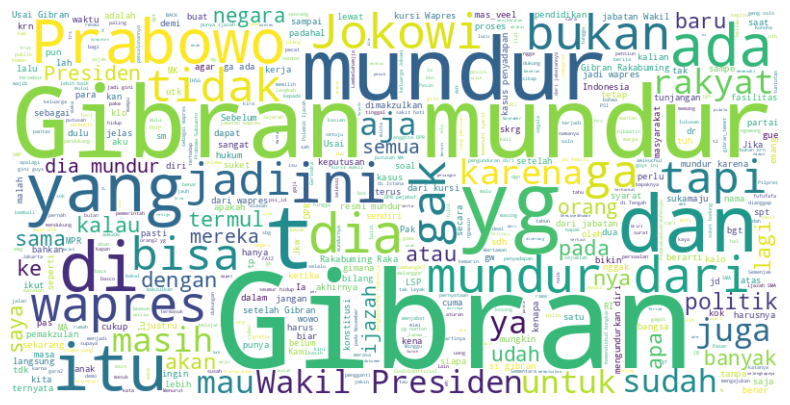

In [ ]:
#cek wordcloud nya
import pandas as pd
import numpy as np
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt

df['full_text'] = df['full_text'].fillna('')

text = ' '.join(df['full_text'].astype(str).tolist())

stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp'])

wc = WordCloud(stopwords=stopwords, background_color='white', max_words=500, width=800, height=400)
wc.generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()


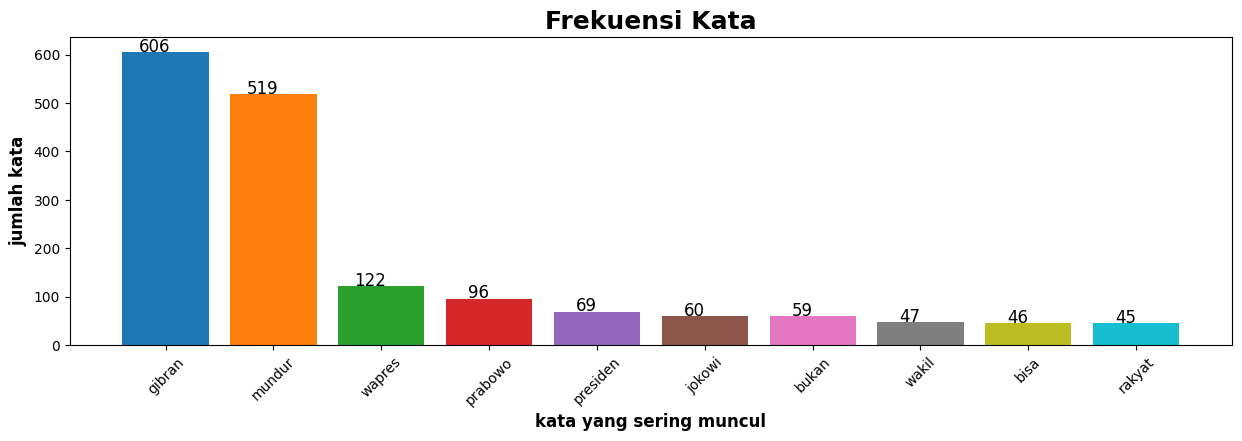

In [ ]:
#untuk mengetahui frekuensi kata
import re
import matplotlib.pyplot as plt
from collections import Counter

# Kata yang dikecualikan
stopwords = {
    'yg', 'yang', 'dari', 'di', 'itu', 'dia', 'ke', 'dan', 'ini', 'untuk',
    'dengan', 'ga', 'gak', 'nggak', 'tidak', 'sih', 'aja', 'juga', 'ada',
    'kan', 'nya', 'pada', 'dalam', 'saya', 'aku', 'lu', 'kamu', 'rt', 'https','co','jadi','karena','tapi'
}

# Gabungkan teks, lowercase, lalu ambil kata saja (buang tanda baca)
text = " ".join(df['full_text']).lower()
tokens = re.findall(r'\b[a-z]+\b', text)

# Saring stopwords dan kata 1 huruf
tokens = [t for t in tokens if t not in stopwords and len(t) > 1]

words_counts = Counter(tokens)

top_words = words_counts.most_common(10)
word, count = zip(*top_words)
colors = plt.cm.tab10(range(len(word)))

plt.figure(figsize=(15, 4))
bars = plt.bar(word, count, color=colors)
plt.xlabel("kata yang sering muncul", fontsize=12, fontweight='bold')
plt.ylabel("jumlah kata", fontsize=12, fontweight='bold')
plt.title("Frekuensi Kata", fontsize=18, fontweight='bold')
plt.xticks(rotation=45)

for bar, num in zip(bars, count):
    plt.text(bar.get_x() + bar.get_width() / 2 - 0.1, num + 1, str(num), fontsize=12, color='black', ha='center')

plt.show()

**CLEANING 2**

In [ ]:
import re
import string
import nltk

# menghapus emoji
def remove_emoji(tweet):
    if tweet is not None and isinstance(tweet, str):
        emoji_pattern = re.compile(
            "["
            u"\U0001F600-\U0001F64F"  # emoticons
            u"\U0001F300-\U0001F5FF"  # symbols & pictographs
            u"\U0001F680-\U0001F6FF"  # transport & map symbols
            u"\U0001F700-\U0001F77F"  # alchemical symbols
            u"\U0001F780-\U0001F7FF"  # Geometric Shapes Extended
            u"\U0001F800-\U0001F8FF"  # Supplemental Arrows-C
            u"\U0001F900-\U0001F9FF"  # Supplemental Symbols and Pictographs
            u"\U0001FA00-\U0001FA6F"  # Chess Symbols
            u"\U0001FA70-\U0001FAFF"  # Symbols and Pictographs Extended-A
            u"\U0001F004-\U0001F0CF"  # Additional emoticons
            u"\U0001F1E0-\U0001F1FF"  # flags
            "]+",
            flags=re.UNICODE
        )
        return emoji_pattern.sub(r'', tweet)
    else:
        return tweet

# menghapus url
def remove_url(text):
    return re.sub(r'http\S+|www.\S+', '', text)

# menghapus hashtag
def remove_hashtag(text):
    return re.sub(r'#\w+', '', text)

# menghapus simbol
def remove_symbols(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'[^a-zA-Z0-9\s]', '', tweet)
    return tweet

# menghapus angka
def remove_numbers(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'\d', '', tweet)
    return tweet

# menghapus username
def remove_username(text):
    return re.sub(r'@[^\s]+', '', text)

# menghapus ekspresi tertawa
def remove_laughing(text):
    return re.sub(r'\b(?:wkwk|wk|kwkwk|haha|hehe|hihi|huha|lol|lmao)+\b', '', text, flags=re.IGNORECASE)

# menangani negasi
def handle_negation(text):
    if text is not None and isinstance(text, str):
        pos_words = ['senang', 'bagus', 'baik', 'puas', 'suka', 'cocok', 'indah', 'nyaman', 'lancar', 'cepat']
        for word in pos_words:
            text = re.sub(rf'\b(tidak|nggak|kurang)\s+{word}\b', f'tidak_{word}', text)
    return text

# Terapkan cleaning
df['cleaning'] = df['full_text'].apply(lambda x: remove_username(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_emoji(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_url(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_hashtag(x))  # <-- tambahan ini
df['cleaning'] = df['cleaning'].apply(lambda x: remove_symbols(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_numbers(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_laughing(x))
df['cleaning'] = df['cleaning'].apply(lambda x: handle_negation(x))

df.head(10)

,created_at,full_text,cleaning
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...
5,2026-11-16 07:00:02,Keputusan Gibran Rakabuming Raka mundur dari j...,Keputusan Gibran Rakabuming Raka mundur dari j...
6,2026-11-16 06:53:30,"@tham878 Hahahhaha ya seperti dugaan kita2,pal...",Hahahhaha ya seperti dugaan kitapaling yg dik...
7,2026-11-16 06:47:24,"Lega setelah Gibran mundur, belakangan baru ta...",Lega setelah Gibran mundur belakangan baru tah...
8,2026-11-16 06:43:50,Baca selengkapnya: https://t.co/pnXy8GL66l\n\n...,Baca selengkapnya \n\nSudah telanjur mencetak ...
9,2026-11-16 06:38:41,@SigitWasito8 Dia pikir dia keren hahaha..\nEh...,Dia pikir dia keren hahaha\nEh ibu saya juga ...


**TEXT FOLDING**

In [ ]:
def case_folding(text):
  if isinstance(text, str):
    lowercase_text = text.lower() #menyeragamkan kata dengan huruf kecil semua
    return lowercase_text
  else:
    return text

df['case_folding'] = df['cleaning'].apply(case_folding)
df.head(25)

,created_at,full_text,cleaning,case_folding
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...
5,2026-11-16 07:00:02,Keputusan Gibran Rakabuming Raka mundur dari j...,Keputusan Gibran Rakabuming Raka mundur dari j...,keputusan gibran rakabuming raka mundur dari j...
6,2026-11-16 06:53:30,"@tham878 Hahahhaha ya seperti dugaan kita2,pal...",Hahahhaha ya seperti dugaan kitapaling yg dik...,hahahhaha ya seperti dugaan kitapaling yg dik...
7,2026-11-16 06:47:24,"Lega setelah Gibran mundur, belakangan baru ta...",Lega setelah Gibran mundur belakangan baru tah...,lega setelah gibran mundur belakangan baru tah...
8,2026-11-16 06:43:50,Baca selengkapnya: https://t.co/pnXy8GL66l\n\n...,Baca selengkapnya \n\nSudah telanjur mencetak ...,baca selengkapnya \n\nsudah telanjur mencetak ...
9,2026-11-16 06:38:41,@SigitWasito8 Dia pikir dia keren hahaha..\nEh...,Dia pikir dia keren hahaha\nEh ibu saya juga ...,dia pikir dia keren hahaha\neh ibu saya juga ...


**NORMALISASI KATA**

In [ ]:
import pandas as pd
import requests
from io import BytesIO

# Fungsi penggantian kata tidak baku
def replace_taboo_words(text, kamus_tidak_baku):
    if isinstance(text, str):
        words = text.split()
        replaced_words = []
        kalimat_baku = []
        kata_diganti = []
        kata_tidak_baku_hash = []

        for word in words:
            if word in kamus_tidak_baku:
                baku_word = kamus_tidak_baku[word]
                if isinstance(baku_word, str) and all(char.isalpha() for char in baku_word):
                    replaced_words.append(baku_word)
                    kalimat_baku.append(baku_word)
                    kata_diganti.append(word)
                    kata_tidak_baku_hash.append(hash(word))
            else:
                replaced_words.append(word)  # kata tidak ada di kamus, tetap dipakai

        replaced_text = ' '.join(replaced_words)
    else:
        replaced_text = ''
        kalimat_baku = []
        kata_diganti = []
        kata_tidak_baku_hash = []

    return replaced_text, kalimat_baku, kata_diganti, kata_tidak_baku_hash

# Contoh ambil subset data (pastikan df sudah ada sebelumnya)
data = pd.DataFrame(df[['created_at','full_text', 'cleaning', 'case_folding']])
data.head(5)


,created_at,full_text,cleaning,case_folding
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...


In [ ]:
import pandas as pd

# Baca file Excel dari path lokal
kamus_data = pd.read_excel('kamuskatabaku.xlsx')

# Buat dictionary dari kamus
kamus_tidak_baku = dict(zip(kamus_data['tidak_baku'], kamus_data['kata_baku']))

In [ ]:
#penerapan fungsi normalisasi

data[['normalisasi', 'Kata_Baku', 'Kata_Tidak_Baku', 'Kata_Tidak_Baku_Hash']] = data['case_folding'].apply(lambda x: pd.Series(replace_taboo_words(x, kamus_tidak_baku)))

df = pd.DataFrame(data[['created_at','full_text', 'cleaning', 'case_folding', 'normalisasi']])

df.head(5)

,created_at,full_text,cleaning,case_folding,normalisasi
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos kalau mereka berd...
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...,dari anies hingga mahfud md intip tokoh masuk ...
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...,faiz adalah hero baru wartawan gibran mundur m...
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...,bacot selvie suami kamu pas mau mundur saja so...
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...,belajar lagi untuk menganalisa situasi perpoli...


**TOKENIZATION**

In [ ]:
def tokenize(text):
  tokens = text.split()
  return tokens

df['tokenize'] = df['normalisasi'].apply(tokenize)

df.head(5)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos kalau mereka berd...,"[saya, selalu, bilang, di, medsos, kalau, mere..."
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...,dari anies hingga mahfud md intip tokoh masuk ...,"[dari, anies, hingga, mahfud, md, intip, tokoh..."
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...,faiz adalah hero baru wartawan gibran mundur m...,"[faiz, adalah, hero, baru, wartawan, gibran, m..."
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...,bacot selvie suami kamu pas mau mundur saja so...,"[bacot, selvie, suami, kamu, pas, mau, mundur,..."
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...,belajar lagi untuk menganalisa situasi perpoli...,"[belajar, lagi, untuk, menganalisa, situasi, p..."


**STOPWORLD REMOVAL**

In [ ]:
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = stopwords.words('indonesian')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
negasi = [
    'tidak', 'nggak', 'enggak', 'gak', 'ga',
    'bukan', 'belum', 'kurang', 'tak', 'jangan'
]

stop_words = [
    word for word in stopwords.words('indonesian')
    if word not in negasi
]

In [ ]:
def remove_stopwords(text):
  return[word for word in text if word not in stop_words]

df['stopword removal'] = df['tokenize'].apply(lambda x: remove_stopwords(x))

df.head(5)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos kalau mereka berd...,"[saya, selalu, bilang, di, medsos, kalau, mere...","[bilang, medsos, berdua, deal, khusus, dukunga..."
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...,dari anies hingga mahfud md intip tokoh masuk ...,"[dari, anies, hingga, mahfud, md, intip, tokoh...","[anies, mahfud, md, intip, tokoh, masuk, bursa..."
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...,faiz adalah hero baru wartawan gibran mundur m...,"[faiz, adalah, hero, baru, wartawan, gibran, m...","[faiz, hero, wartawan, gibran, mundur, menurut..."
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...,bacot selvie suami kamu pas mau mundur saja so...,"[bacot, selvie, suami, kamu, pas, mau, mundur,...","[bacot, selvie, suami, pas, mundur, sokan, pos..."
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...,belajar lagi untuk menganalisa situasi perpoli...,"[belajar, lagi, untuk, menganalisa, situasi, p...","[belajar, menganalisa, situasi, perpolitikan, ..."


**STEMMING DATA**

In [ ]:
!pip install Sastrawi

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from nltk.stem import PorterStemmer
from nltk.stem.snowball import SnowballStemmer

In [ ]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stem_text(text):
  return [stemmer.stem(word) for word in text]

df['stemming_data'] = df['stopword removal'].apply(lambda x: ' '.join(stem_text(x)))
df.to_excel('hasilpreprocessing_miniproject.xlsx', index=False)
df.head(5)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,stemming_data
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos kalau mereka berd...,"[saya, selalu, bilang, di, medsos, kalau, mere...","[bilang, medsos, berdua, deal, khusus, dukunga...",bilang medsos dua deal khusus dukung jokowi pr...
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...,dari anies hingga mahfud md intip tokoh masuk ...,"[dari, anies, hingga, mahfud, md, intip, tokoh...","[anies, mahfud, md, intip, tokoh, masuk, bursa...",anies mahfud md intip tokoh masuk bursa ganti ...
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...,faiz adalah hero baru wartawan gibran mundur m...,"[faiz, adalah, hero, baru, wartawan, gibran, m...","[faiz, hero, wartawan, gibran, mundur, menurut...",faiz hero wartawan gibran mundur turut ganti f...
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...,bacot selvie suami kamu pas mau mundur saja so...,"[bacot, selvie, suami, kamu, pas, mau, mundur,...","[bacot, selvie, suami, pas, mundur, sokan, pos...",bacot selvie suami pas mundur sok posting giat...
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...,belajar lagi untuk menganalisa situasi perpoli...,"[belajar, lagi, untuk, menganalisa, situasi, p...","[belajar, menganalisa, situasi, perpolitikan, ...",ajar menganalisa situasi politik bro bukan ban...


In [ ]:
#cek kolom

print(data.columns)

Index(['created_at', 'full_text', 'cleaning', 'case_folding', 'normalisasi',
       'Kata_Baku', 'Kata_Tidak_Baku', 'Kata_Tidak_Baku_Hash'],
      dtype='object')


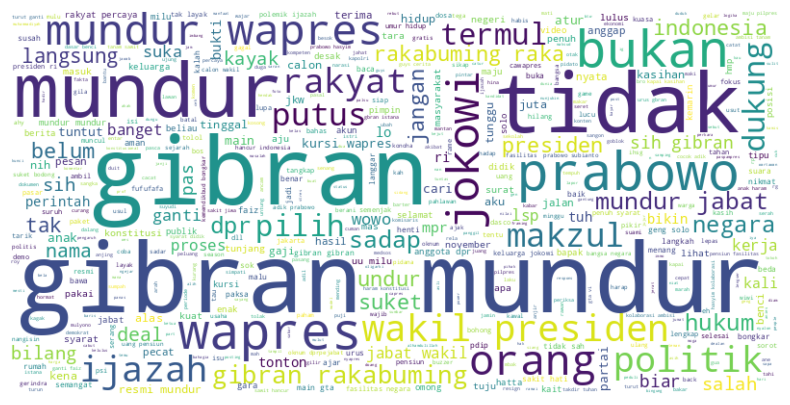

In [ ]:
# Cek WordCloud-nya
import pandas as pd
import numpy as np
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt

# 1. Baca file Excel langsung
df = pd.read_excel('hasilpreprocessing_miniproject.xlsx')  # Ganti sesuai nama file kamu

# 2. Ambil dan gabungkan teks dari kolom stemming_data
text = ' '.join(df['stemming_data'].astype(str).tolist())

# 3. Tambahkan stopwords khusus
stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp', 'lu', 'deh', 'fyp', 'ya', 'gue', 'kak'])

# 4. Generate WordCloud
wc = WordCloud(stopwords=stopwords, background_color='white', max_words=500, width=800, height=400)
wc.generate(text)

# 5. Tampilkan
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()


In [ ]:
import pandas as pd

df = pd.read_excel('hasilpreprocessing_miniproject.xlsx')
print(df.columns.tolist())

['created_at', 'full_text', 'cleaning', 'case_folding', 'normalisasi', 'tokenize', 'stopword removal', 'stemming_data']


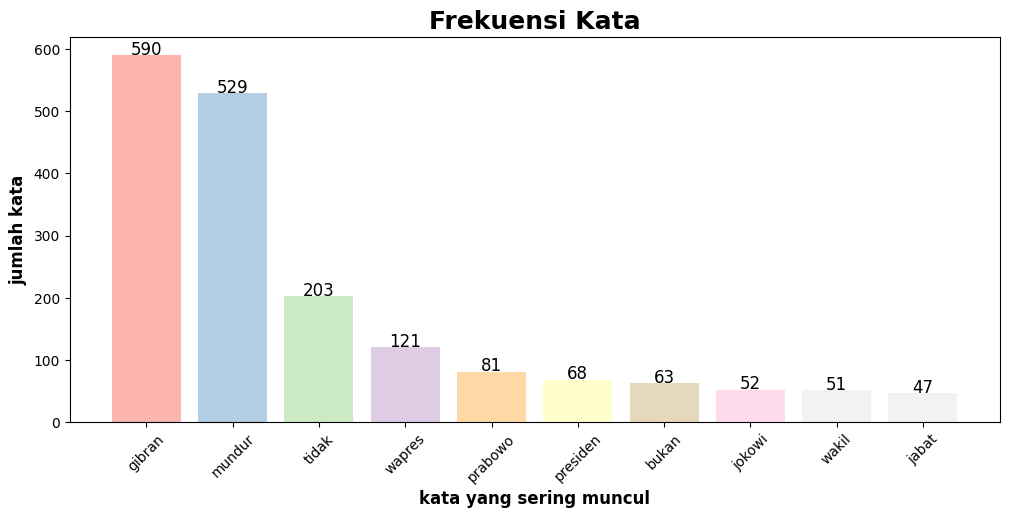

In [ ]:
#frekuensi kata
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import STOPWORDS

text = " ".join(df['stemming_data'].astype(str))

stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp', 'lu', 'deh', 'fyp', 'ya', 'gue', 'kak'])

tokens = [word for word in text.split() if word not in stopwords]
words_counts = Counter(tokens)

top_words = words_counts.most_common(10)
word, count = zip(*top_words)
colors = plt.cm.Pastel1(range(len(word)))

plt.figure(figsize=(12, 5))
bars = plt.bar(word, count, color=colors)
plt.xlabel("kata yang sering muncul", fontsize=12, fontweight='bold')
plt.ylabel("jumlah kata", fontsize=12, fontweight='bold')
plt.title("Frekuensi Kata", fontsize=18, fontweight='bold')
plt.xticks(rotation=45)

for bar, num in zip(bars, count):
    plt.text(bar.get_x() + bar.get_width() / 1.6 - 0.1, num + 1, str(num), fontsize=12, color='black', ha='center')

plt.show()#menampilkan diagram


**INDOBERT**

In [ ]:
!pip install transformers torch

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load model IndoBERT Sentiment Analysis
model_name = "crypter70/IndoBERT-Sentiment-Analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Buat pipeline untuk analisis sentimen
sentiment_pipe = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/709k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
import pandas as pd

# Load file CSV
df = pd.read_excel('hasilpreprocessing_miniproject.xlsx')

df[['normalisasi']].head()

,normalisasi
0,saya selalu bilang di medsos kalau mereka berd...
1,dari anies hingga mahfud md intip tokoh masuk ...
2,faiz adalah hero baru wartawan gibran mundur m...
3,bacot selvie suami kamu pas mau mundur saja so...
4,belajar lagi untuk menganalisa situasi perpoli...


In [ ]:
def get_sentiment(text):
    try:
        result = sentiment_pipe(text)[0]
        label = result['label']
        score = result['score']

        # Mapping label IndoBERT
        mapping = {
            'LABEL_0': 'positive',
            'LABEL_1': 'neutral',
            'LABEL_2': 'negative'
        }

        return mapping.get(label, label), score
    except:
        return None, None

In [ ]:
# Membersihkan kolom dari NaN atau baris kosong
df = df[df['normalisasi'].notna()]
df = df[df['normalisasi'].str.strip() != '']
df.loc[:, 'normalisasi'] = df['normalisasi'].astype(str)
df = df.reset_index(drop=True)

# Terapkan label sentimen
df['sent_label'], df['sent_score'] = zip(*df['normalisasi'].apply(get_sentiment))


In [ ]:
import pandas as pd

# Terapkan labeling ke seluruh data
df['sent_label'], df['sent_score'] = zip(*df['normalisasi'].apply(get_sentiment))

# Cek hasil awal
df[['normalisasi', 'sent_label', 'sent_score']]
df.head(30)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,stemming_data,sent_label,sent_score
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos kalau mereka berd...,"['saya', 'selalu', 'bilang', 'di', 'medsos', '...","['bilang', 'medsos', 'berdua', 'deal', 'khusus...",bilang medsos dua deal khusus dukung jokowi pr...,NEGATIVE,0.999944
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...,dari anies hingga mahfud md intip tokoh masuk ...,"['dari', 'anies', 'hingga', 'mahfud', 'md', 'i...","['anies', 'mahfud', 'md', 'intip', 'tokoh', 'm...",anies mahfud md intip tokoh masuk bursa ganti ...,NEUTRAL,0.999917
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...,faiz adalah hero baru wartawan gibran mundur m...,"['faiz', 'adalah', 'hero', 'baru', 'wartawan',...","['faiz', 'hero', 'wartawan', 'gibran', 'mundur...",faiz hero wartawan gibran mundur turut ganti f...,NEGATIVE,0.999842
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...,bacot selvie suami kamu pas mau mundur saja so...,"['bacot', 'selvie', 'suami', 'kamu', 'pas', 'm...","['bacot', 'selvie', 'suami', 'pas', 'mundur', ...",bacot selvie suami pas mundur sok posting giat...,NEGATIVE,0.999954
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...,belajar lagi untuk menganalisa situasi perpoli...,"['belajar', 'lagi', 'untuk', 'menganalisa', 's...","['belajar', 'menganalisa', 'situasi', 'perpoli...",ajar menganalisa situasi politik bro bukan ban...,NEGATIVE,0.999933
5,2026-11-16 07:00:02,Keputusan Gibran Rakabuming Raka mundur dari j...,Keputusan Gibran Rakabuming Raka mundur dari j...,keputusan gibran rakabuming raka mundur dari j...,keputusan gibran rakabuming raka mundur dari j...,"['keputusan', 'gibran', 'rakabuming', 'raka', ...","['keputusan', 'gibran', 'rakabuming', 'raka', ...",putus gibran rakabuming raka mundur jabat waki...,NEUTRAL,0.999915
6,2026-11-16 06:53:30,"@tham878 Hahahhaha ya seperti dugaan kita2,pal...",Hahahhaha ya seperti dugaan kitapaling yg dik...,hahahhaha ya seperti dugaan kitapaling yg dik...,hahahhaha ya seperti dugaan kitapaling yang di...,"['hahahhaha', 'ya', 'seperti', 'dugaan', 'kita...","['hahahhaha', 'ya', 'dugaan', 'kitapaling', 'd...",hahahhaha ya duga kitapaling dikontenin sih gi...,NEGATIVE,0.999915
7,2026-11-16 06:47:24,"Lega setelah Gibran mundur, belakangan baru ta...",Lega setelah Gibran mundur belakangan baru tah...,lega setelah gibran mundur belakangan baru tah...,lega setelah gibran mundur belakangan baru tah...,"['lega', 'setelah', 'gibran', 'mundur', 'belak...","['lega', 'gibran', 'mundur', 'proses', 'kursi'...",lega gibran mundur proses kursi wapres penuh r...,NEGATIVE,0.999944
8,2026-11-16 06:43:50,Baca selengkapnya: https://t.co/pnXy8GL66l\n\n...,Baca selengkapnya \n\nSudah telanjur mencetak ...,baca selengkapnya \n\nsudah telanjur mencetak ...,baca selengkapnya sudah telanjur mencetak ratu...,"['baca', 'selengkapnya', 'sudah', 'telanjur', ...","['baca', 'selengkapnya', 'telanjur', 'mencetak...",baca lengkap telanjur cetak ratus foto dagang ...,NEUTRAL,0.999860
9,2026-11-16 06:38:41,@SigitWasito8 Dia pikir dia keren hahaha..\nEh...,Dia pikir dia keren hahaha\nEh ibu saya juga ...,dia pikir dia keren hahaha\neh ibu saya juga ...,dia pikir dia keren hahaha eh ibu saya juga sa...,"['dia', 'pikir', 'dia', 'keren', 'hahaha', 'eh...","['pikir', 'keren', 'hahaha', 'eh', 'setuju', '...",pikir keren hahah

In [ ]:
df.to_excel('hasillabeling_miniproject.xlsx', index=False)

Persentase Sentimen:
sent_label
NEGATIVE    60.48
NEUTRAL     31.85
POSITIVE     7.66
Name: proportion, dtype: float64


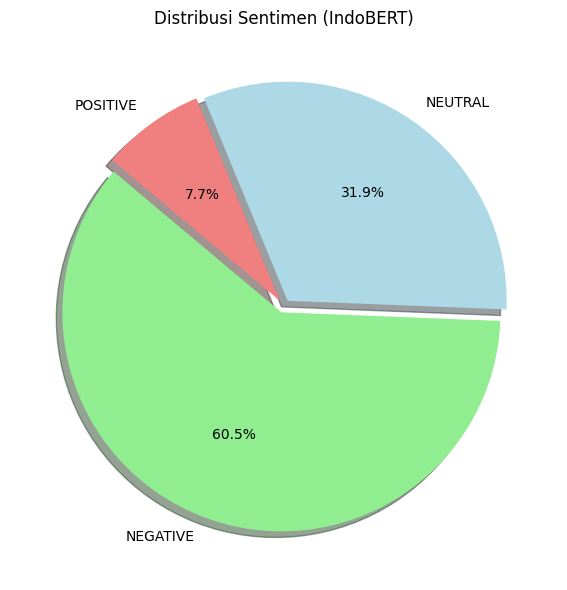

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# hitung persentase masing-masing sentimen
label_counts = df['sent_label'].value_counts(normalize=True) * 100

# ditampilkan dengan angka
print("Persentase Sentimen:")
print(label_counts.round(2))

# visualisasi pie chart
plt.figure(figsize=(6, 6))
colors = ['lightgreen', 'lightblue','lightcoral']  # NEGATIVE, NEUTRAL, POSITIVE
label_counts.plot(kind='pie',
                  autopct='%1.1f%%',
                  colors=colors,
                  startangle=140,
                  shadow=True,
                  explode=(0.03, 0.03, 0.03))

plt.title('Distribusi Sentimen (IndoBERT)')
plt.ylabel('')  # hilangkan label y
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load data
df = pd.read_excel('hasillabeling_miniproject.xlsx')

# Encode label (pastikan kolom label bernama 'sent_label')
label_encoder = LabelEncoder()
df['encoded_label'] = label_encoder.fit_transform(df['sent_label'])


In [ ]:
print(tokenizer.vocab_size)  # ✅ jumlah token dalam vocab IndoBERT

30521


In [ ]:
df['normalisasi'] = df['normalisasi'].fillna('').astype(str)

In [ ]:
# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(df['normalisasi'])

sequences = tokenizer.texts_to_sequences(df['normalisasi'])

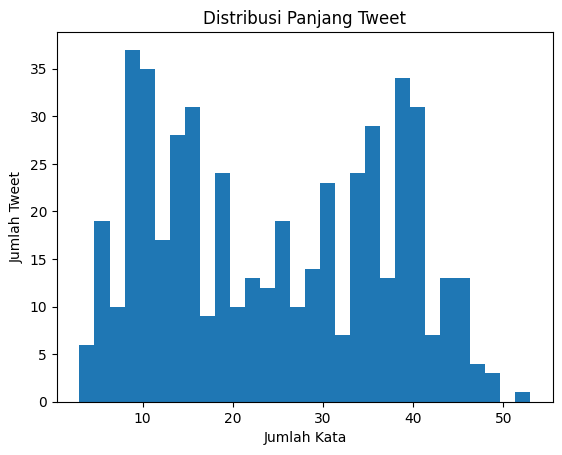

In [ ]:
import matplotlib.pyplot as plt

# Hitung panjang setiap tweet
tweet_lengths = [len(tweet.split()) for tweet in df['normalisasi']]

# Visualisasikan distribusinya
plt.hist(tweet_lengths, bins=30)
plt.title('Distribusi Panjang Tweet')
plt.xlabel('Jumlah Kata')
plt.ylabel('Jumlah Tweet')
plt.show()

In [ ]:
# Padding
max_len = 100  # distribusi panjang teks
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

In [ ]:
from tensorflow.keras.utils import to_categorical

# One-hot encoding untuk label
onehot_labels = to_categorical(df['encoded_label'], num_classes=3)

# 0 → [1. 0. 0.]
# 1 → [0. 1. 0.]
# 2 → [0. 0. 1.]


In [ ]:
df.head(25)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,stemming_data,sent_label,sent_score,encoded_label
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos kalau mereka berd...,"['saya', 'selalu', 'bilang', 'di', 'medsos', '...","['bilang', 'medsos', 'berdua', 'deal', 'khusus...",bilang medsos dua deal khusus dukung jokowi pr...,NEGATIVE,0.999944,0
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...,dari anies hingga mahfud md intip tokoh masuk ...,"['dari', 'anies', 'hingga', 'mahfud', 'md', 'i...","['anies', 'mahfud', 'md', 'intip', 'tokoh', 'm...",anies mahfud md intip tokoh masuk bursa ganti ...,NEUTRAL,0.999917,1
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...,faiz adalah hero baru wartawan gibran mundur m...,"['faiz', 'adalah', 'hero', 'baru', 'wartawan',...","['faiz', 'hero', 'wartawan', 'gibran', 'mundur...",faiz hero wartawan gibran mundur turut ganti f...,NEGATIVE,0.999842,0
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...,bacot selvie suami kamu pas mau mundur saja so...,"['bacot', 'selvie', 'suami', 'kamu', 'pas', 'm...","['bacot', 'selvie', 'suami', 'pas', 'mundur', ...",bacot selvie suami pas mundur sok posting giat...,NEGATIVE,0.999954,0
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...,belajar lagi untuk menganalisa situasi perpoli...,"['belajar', 'lagi', 'untuk', 'menganalisa', 's...","['belajar', 'menganalisa', 'situasi', 'perpoli...",ajar menganalisa situasi politik bro bukan ban...,NEGATIVE,0.999933,0
5,2026-11-16 07:00:02,Keputusan Gibran Rakabuming Raka mundur dari j...,Keputusan Gibran Rakabuming Raka mundur dari j...,keputusan gibran rakabuming raka mundur dari j...,keputusan gibran rakabuming raka mundur dari j...,"['keputusan', 'gibran', 'rakabuming', 'raka', ...","['keputusan', 'gibran', 'rakabuming', 'raka', ...",putus gibran rakabuming raka mundur jabat waki...,NEUTRAL,0.999915,1
6,2026-11-16 06:53:30,"@tham878 Hahahhaha ya seperti dugaan kita2,pal...",Hahahhaha ya seperti dugaan kitapaling yg dik...,hahahhaha ya seperti dugaan kitapaling yg dik...,hahahhaha ya seperti dugaan kitapaling yang di...,"['hahahhaha', 'ya', 'seperti', 'dugaan', 'kita...","['hahahhaha', 'ya', 'dugaan', 'kitapaling', 'd...",hahahhaha ya duga kitapaling dikontenin sih gi...,NEGATIVE,0.999915,0
7,2026-11-16 06:47:24,"Lega setelah Gibran mundur, belakangan baru ta...",Lega setelah Gibran mundur belakangan baru tah...,lega setelah gibran mundur belakangan baru tah...,lega setelah gibran mundur belakangan baru tah...,"['lega', 'setelah', 'gibran', 'mundur', 'belak...","['lega', 'gibran', 'mundur', 'proses', 'kursi'...",lega gibran mundur proses kursi wapres penuh r...,NEGATIVE,0.999944,0
8,2026-11-16 06:43:50,Baca selengkapnya: https://t.co/pnXy8GL66l\n\n...,Baca selengkapnya \n\nSudah telanjur mencetak ...,baca selengkapnya \n\nsudah telanjur mencetak ...,baca selengkapnya sudah telanjur mencetak ratu...,"['baca', 'selengkapnya', 'sudah', 'telanjur', ...","['baca', 'selengkapnya', 'telanjur', 'mencetak...",baca lengkap telanjur cetak ratus foto dagang ...,NEUTRAL,0.999860,1
9,2026-11-16 06:38:41,@SigitWasito8 Dia pikir dia keren hahaha..\nEh...,Dia pikir dia keren hahaha\nEh ibu saya juga ...,dia pikir dia keren hahaha\neh ibu saya juga ...,dia pikir dia keren hahaha eh ibu saya juga sa...,"['dia', 'pikir', 'dia', 'keren', 'hahaha', 'eh...","['pikir', 'keren', 'hahaha', 'eh', '

In [ ]:
# Ambil tweet dengan sentimen negatif
negative_df = df[df['sent_label'] == 'NEGATIVE']

# Tampilkan 20 tweet negatif
for tweet in negative_df['normalisasi'].head(20):
    print(tweet)
    print("-" * 80)

saya selalu bilang di medsos kalau mereka berdua itu ada deal khusus di balik dukungan jokowi ke prabowo jadi presiden sekarang gibran dituntut mundur sama rakyat pasti ada lagi deal antara mereka berdua itu saling menutupi amp membela dosa masing lo berani ke gue gue bongkar begitu kira
--------------------------------------------------------------------------------
faiz adalah hero baru wartawan gibran mundur menurutmu siapa yang pantas menggantikan faiz tidak ada yang lebih cocok dari adiknya prabowo sendiri hasyim jika mereka berkolaborasi maka ambisi mereka menanam sawit dan menghancurkan indonesia itu lebih baik lagi faiz membakar
--------------------------------------------------------------------------------
bacot selvie suami kamu pas mau mundur saja sokan posting kegiatan sampai kali kurun waktu jam memang anjing semua lah kalian ya wowok ya hashim ya muloyno ya gibran
--------------------------------------------------------------------------------
belajar lagi untuk menganal

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Total negative tweets: 300

Top 20 Frequent Words in Negative Sentiment:
gibran: 358
mundur: 316
wapres: 58
prabowo: 45
rakyat: 39
orang: 39
jokowi: 36
ijazah: 28
negara: 26
termul: 24
presiden: 22
hukum: 19
suket: 19
indonesia: 18
politik: 18
deal: 16
dpr: 16
kayak: 16
penyadapan: 14
syarat: 14


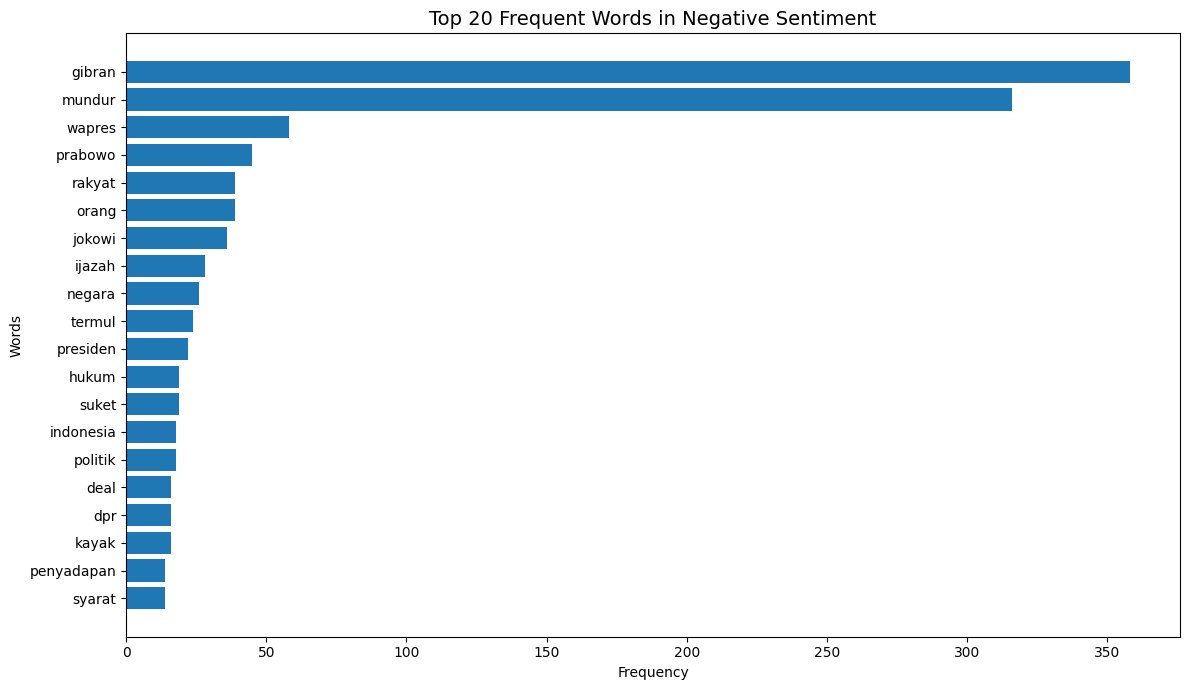

In [ ]:

# NEGATIVE SENTIMENT KEYWORD FREQUENCY
import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt
from collections import Counter
from nltk.corpus import stopwords

# 1. Download Indonesian stopwords
nltk.download('stopwords')

# 2. Define custom stopwords
custom_stopwords = {
    # Common Indonesian words
    'yang', 'dan', 'di', 'ke', 'dari', 'ini',
    'itu', 'ada', 'akan', 'atau', 'juga',
    'karena', 'sama', 'dia', 'mereka', 'kami',
    'kita', 'saya', 'aku', 'ya', 'aja', 'saja',
    'tapi', 'tetapi', 'jadi', 'kalau', 'kalo',
    'sudah', 'udah', 'beliau', 'nya', 'lah',
    'pun', 'dengan', 'untuk', 'pada', 'dalam',
    'oleh', 'sebagai', 'tersebut', 'adalah',
    'bisa', 'dapat', 'masih', 'lebih', 'sangat',
    'hanya', 'bahkan', 'hingga', 'saat', 'ketika',
    'seperti', 'namun', 'maka', 'serta', 'biar','amp',

    # Informal words
    'gue', 'gua', 'sih', 'dong', 'nih', 'deh',
    'loh', 'lho', 'kok', 'pas',

    # Negation words
    'tidak', 'nggak', 'enggak', 'gak', 'ga',
    'bukan', 'belum', 'kurang', 'tak', 'jangan'
}

# 3. Combine NLTK and custom stopwords
stop_words = (
    set(stopwords.words('indonesian'))
    | custom_stopwords
)

# 4. Filter negative sentiment tweets
negative_df = df[
    df['sent_label'] == 'NEGATIVE'
].copy()

print("Total negative tweets:", len(negative_df))

# 5. Remove stopwords
def remove_stopwords(text):
    if pd.isna(text):
        return ''

    words = str(text).lower().split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(filtered_words)

negative_df['clean_text'] = (
    negative_df['normalisasi'].apply(remove_stopwords)
)

# 6. Combine all negative tweets
negative_text = ' '.join(
    negative_df['clean_text'].dropna()
)

# 7. Tokenization
words = re.findall(r'\b\w+\b', negative_text)

# 8. Calculate word frequency
word_freq = Counter(words)

# 9. Display top 20 frequent words
top_words = word_freq.most_common(20)

print("\nTop 20 Frequent Words in Negative Sentiment:")

for word, frequency in top_words:
    print(f"{word}: {frequency}")

# 10. Visualize word frequency
if top_words:
    words, counts = zip(*top_words)

    plt.figure(figsize=(12, 7))
    plt.barh(words[::-1], counts[::-1])

    plt.title(
        'Top 20 Frequent Words in Negative Sentiment',
        fontsize=14
    )
    plt.xlabel('Frequency')
    plt.ylabel('Words')

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada kata yang dapat dianalisis.")

Top 20 Bigrams in Negative Sentiment:


,Bigram,Frequency
3,gibran mundur,166
9,mundur gibran,16
12,mundur wapres,11
19,wakil presiden,8
18,uu pemilu,8
4,gibran wapres,8
11,mundur jabatan,7
2,geng solo,6
17,suka gibran,6
15,rakyat percaya,6


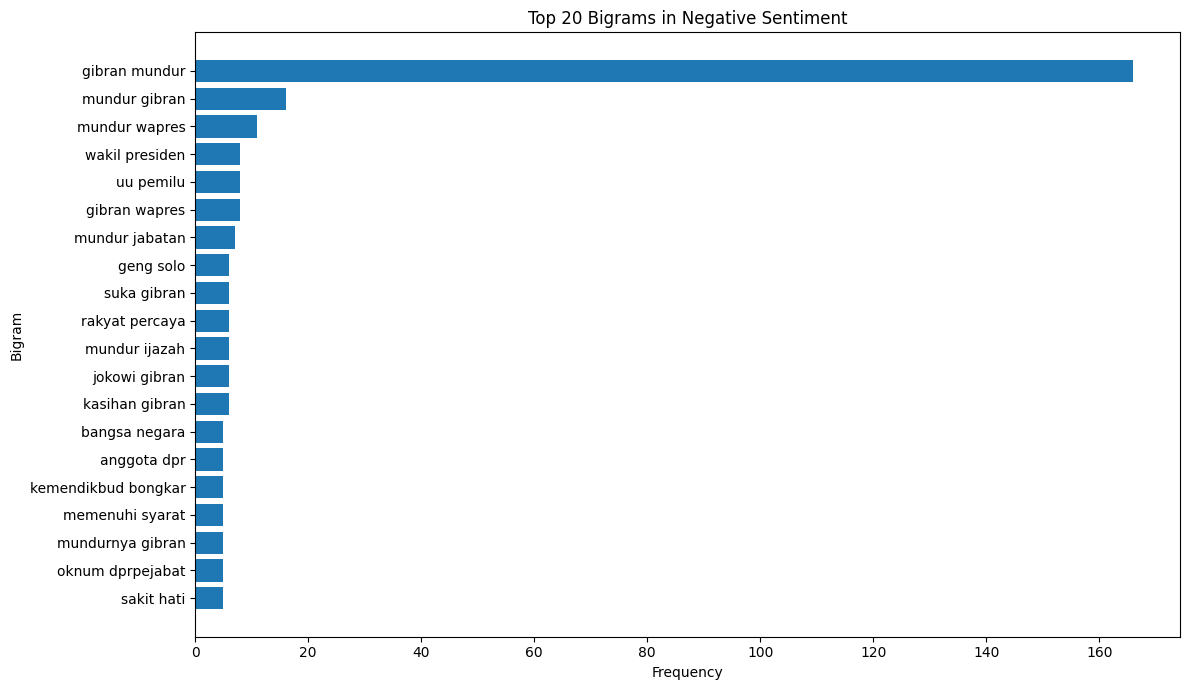

In [ ]:
# BIGRAM ANALYSIS - NEGATIVE SENTIMENT
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare negative tweet text
texts = negative_df['clean_text'].dropna()

# 2. Generate bigrams
vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=20
)

bigram_matrix = vectorizer.fit_transform(texts)

# 3. Calculate bigram frequency
bigram_freq = pd.DataFrame({
    'Bigram': vectorizer.get_feature_names_out(),
    'Frequency': bigram_matrix.sum(axis=0).A1
})

bigram_freq = bigram_freq.sort_values(
    by='Frequency',
    ascending=False
)

# 4. top 20 bigrams
print("Top 20 Bigrams in Negative Sentiment:")
display(bigram_freq)

# 5. Visualize bigram frequency
plt.figure(figsize=(12, 7))

plt.barh(
    bigram_freq['Bigram'].iloc[::-1],
    bigram_freq['Frequency'].iloc[::-1]
)

plt.title('Top 20 Bigrams in Negative Sentiment')
plt.xlabel('Frequency')
plt.ylabel('Bigram')

plt.tight_layout()
plt.show()


In [ ]:
# TOPIC ANALYSIS - TEXT PREPARATION
# Apply stopword removal to all tweets
df['topic_text'] = df['normalisasi'].apply(remove_stopwords)

# Remove empty text
topic_df = df[
    df['topic_text'].notna() &
    (df['topic_text'].str.strip() != '')
].copy()

print("Total tweets for topic analysis:", len(topic_df))

# Display sample
display(topic_df[['normalisasi', 'topic_text']].head(10))

Total tweets for topic analysis: 496


,normalisasi,topic_text
0,saya selalu bilang di medsos kalau mereka berd...,bilang medsos berdua deal khusus dukungan joko...
1,dari anies hingga mahfud md intip tokoh masuk ...,anies mahfud md intip tokoh masuk bursa pengga...
2,faiz adalah hero baru wartawan gibran mundur m...,faiz hero wartawan gibran mundur menurutmu men...
3,bacot selvie suami kamu pas mau mundur saja so...,bacot selvie suami mundur sokan posting kegiat...
4,belajar lagi untuk menganalisa situasi perpoli...,belajar menganalisa situasi perpolitikan bro b...
5,keputusan gibran rakabuming raka mundur dari j...,keputusan gibran rakabuming raka mundur jabata...
6,hahahhaha ya seperti dugaan kitapaling yang di...,hahahhaha dugaan kitapaling dikontenin gibran ...
7,lega setelah gibran mundur belakangan baru tah...,lega gibran mundur proses kursi wapres penuh r...
8,baca selengkapnya sudah telanjur mencetak ratu...,baca selengkapnya telanjur mencetak ratusan fo...
9,dia pikir dia keren hahaha eh ibu saya juga sa...,pikir keren hahaha eh setuju gibran mundur kes...


In [ ]:
# 1. TF-IDF VECTORIZATION

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=1000,
    min_df=2,
    max_df=0.90,
    ngram_range=(1, 2)
)

# Transform text into TF-IDF matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(
    topic_df['topic_text']
)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Number of Documents:", tfidf_matrix.shape[0])
print("Number of Features:", tfidf_matrix.shape[1])

TF-IDF Matrix Shape: (496, 1000)
Number of Documents: 496
Number of Features: 1000


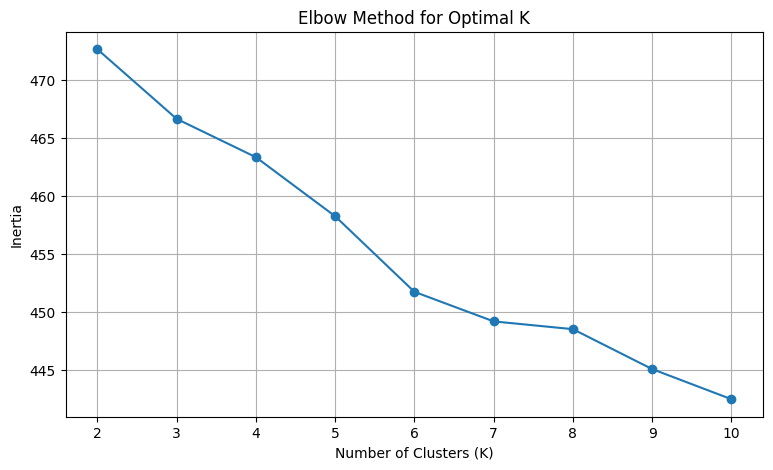

In [ ]:
# ELBOW METHOD
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(tfidf_matrix)
    inertia_values.append(kmeans.inertia_)

# Visualize Elbow Method
plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    inertia_values,
    marker='o'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

Cluster Distribution:
cluster
0     22
1     47
2     62
3     96
4    258
5     11
Name: count, dtype: int64


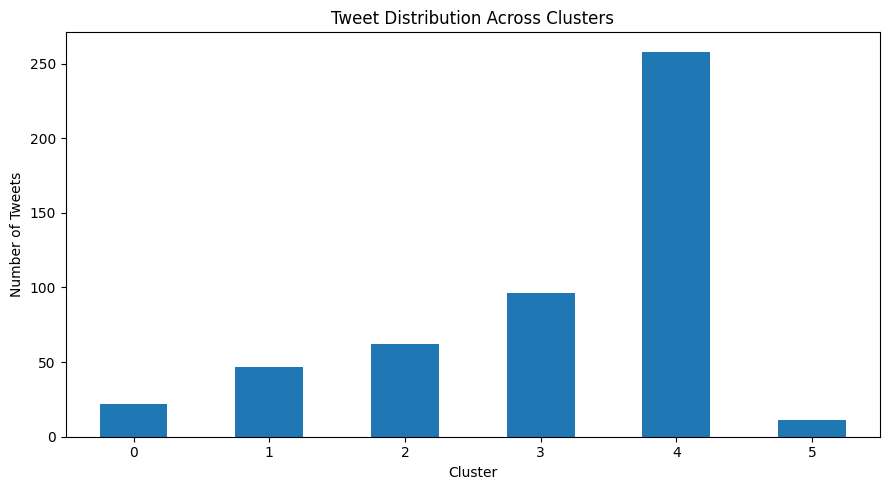

In [ ]:
# K-MEANS CLUSTERING
from sklearn.cluster import KMeans

# Set number of clusters
optimal_k = 6

# Initialize K-Means
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Fit model and assign cluster labels
topic_df['cluster'] = kmeans.fit_predict(tfidf_matrix)

# Display cluster distribution
cluster_counts = topic_df['cluster'].value_counts().sort_index()

print("Cluster Distribution:")
print(cluster_counts)

# Visualize cluster distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
cluster_counts.plot(kind='bar')

plt.title('Tweet Distribution Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# TOP TERMS PER CLUSTER

terms = tfidf_vectorizer.get_feature_names_out()

order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

for i in range(optimal_k):

    print(f"\nCLUSTER {i}")

    top_terms = [
        terms[ind]
        for ind in order_centroids[i, :10]
    ]

    print(", ".join(top_terms))


CLUSTER 0
kayak, resmi, resmi mundur, kayak gibran, gibran kayak, mundur kayak, gibran resmi, mencari, wowo, wapres

CLUSTER 1
wakil, presiden, wakil presiden, rakabuming, gibran rakabuming, jabatan, raka, rakabuming raka, jabatan wakil, mundur jabatan

CLUSTER 2
wapres, mundur wapres, gibran mundur, mas, mas gibran, maju, wapres gibran, fasilitas, kursi, kursi wapres

CLUSTER 3
prabowo, jokowi, gibran mundur, rakyat, deal, politik, keluarga, mundur gibran, faiz, indonesia

CLUSTER 4
gibran mundur, termul, orang, ijazah, dpr, mundur gibran, suka, negara, suket, menonton

CLUSTER 5
gibran mundur, kapolri, kantor, kandidat, kampung, kamis, kalimat, kali, kalah telak, kalah


In [ ]:
# Ambil sampel tweet dari Cluster 4
cluster_4 = topic_df[topic_df['cluster'] == 4]

print("Total tweets in Cluster 4:", len(cluster_4))

for i, tweet in enumerate(cluster_4['normalisasi'].head(20), 1):
    print(f"{i}. {tweet}")
    print("-" * 100)

Total tweets in Cluster 4: 258
1. bacot selvie suami kamu pas mau mundur saja sokan posting kegiatan sampai kali kurun waktu jam memang anjing semua lah kalian ya wowok ya hashim ya muloyno ya gibran
----------------------------------------------------------------------------------------------------
2. belajar lagi untuk menganalisa situasi perpolitikan bro kalau bukan saat ini yang bantu bos kamu itu sudah pasti ikut ditahan dimako brimob bersm para jenderal pimpinan lspgibran mundur disamping karena putusan sama amp maka ada sesuatu yang harus dia selamatkan akibat penyadapan itu
----------------------------------------------------------------------------------------------------
3. hahahhaha ya seperti dugaan kitapaling yang dikontenin sih gibran ini keluargajalan dan game memang isi kepala ya tidak ada alias kosongsyukur akhirnya dia mundurberkurang orang indonesia yang tidak kompeten duduk jadi pejabat
--------------------------------------------------------------------------------

In [ ]:

import pandas as pd
from google.colab import files

# 1. Collect tweets from each cluster
cluster_samples = []

for cluster_id in sorted(topic_df['cluster'].unique()):

    samples = topic_df[
        topic_df['cluster'] == cluster_id
    ]['normalisasi'].dropna().head(10)

    for i, tweet in enumerate(samples, 1):
        cluster_samples.append({
            'cluster': cluster_id,
            'sample_number': i,
            'tweet': tweet
        })

# 2. Create DataFrame
samples_df = pd.DataFrame(cluster_samples)

# 3. Export to Excel
output_file = 'hasilsampel_per_cluster.xlsx'

samples_df.to_excel(output_file, index=False)

# 4. Check result
print("Total samples:", len(samples_df))
print(samples_df.groupby('cluster').size())

# 5. Download Excel
files.download(output_file)


Total samples: 60
cluster
0    10
1    10
2    10
3    10
4    10
5    10
dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#cekdataasli
# Load data
df = pd.read_excel('dataasli_updated.xlsx')
print(df.columns.tolist())
print(df[['user_id_str', 'created_at', 'normalisasi']].head())

['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'normalisasi']
           user_id_str          created_at  \
0  1709419397021093888 2026-11-16 07:30:34   
1  1243804423001763840 2026-11-16 07:30:00   
2  2106994440296669184 2026-11-16 07:30:00   
3  1518351214378815488 2026-11-16 07:30:00   
4  1123868420242591744 2026-11-16 07:21:55   

                                         normalisasi  
0  saya selalu bilang di medsos kalau mereka berd...  
1  dari anies hingga mahfud md intip tokoh masuk ...  
2  faiz adalah hero baru wartawan gibran mundur m...  
3  bacot selvie suami kamu pas mau mundur saja so...  
4  belajar lagi untuk menganalisa situasi perpoli...  


In [ ]:

coord_df = pd.read_excel('dataasli_updated.xlsx')
print(coord_df.columns.tolist())
coord_df = coord_df.dropna(subset=['full_text']).copy()
coord_df['full_text'] = coord_df['full_text'].astype(str)

# TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    min_df=1,
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=True
)

tfidf_matrix = tfidf_vectorizer.fit_transform(coord_df['full_text'])

# Periksa hasil
print("Jumlah unggahan:", tfidf_matrix.shape[0])
print("Jumlah fitur:", tfidf_matrix.shape[1])
print("Dimensi TF-IDF:", tfidf_matrix.shape)

['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'normalisasi']
Jumlah unggahan: 500
Jumlah fitur: 5000
Dimensi TF-IDF: (500, 5000)


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# 1. Hitung cosine similarity
similarity_matrix = cosine_similarity(tfidf_matrix)

# 2. Ambil pasangan unggahan yang tidak membandingkan dirinya sendiri
np.fill_diagonal(similarity_matrix, 0)

# 3. Buat daftar pasangan unggahan
similarity_pairs = []

for i in range(similarity_matrix.shape[0]):
    for j in range(i + 1, similarity_matrix.shape[1]):
        similarity_pairs.append({
            'tweet_1_index': i,
            'tweet_2_index': j,
            'similarity_score': similarity_matrix[i, j]
        })

similarity_df = pd.DataFrame(similarity_pairs)

# 4. Urutkan dari kemiripan tertinggi
similarity_df = similarity_df.sort_values(
    by='similarity_score',
    ascending=False
).reset_index(drop=True)

# 5. Tampilkan 20 pasangan teratas
similarity_df.head(20)

,tweet_1_index,tweet_2_index,similarity_score
0,2,93,1.000000
1,78,93,0.990638
2,2,78,0.990638
3,382,385,0.982711
4,380,382,0.967119
5,380,385,0.967119
6,323,330,0.926719
7,323,335,0.926719
8,323,463,0.926719
9,335,463,0.926719


In [ ]:
# Ambilpasangandengan similarity tertinggi
top_pairs = similarity_df.head(20).copy()

pair_details = []

for _, row in top_pairs.iterrows():

    i = int(row['tweet_1_index'])
    j = int(row['tweet_2_index'])

    tweet_1 = coord_df.iloc[i]
    tweet_2 = coord_df.iloc[j]

    pair_details.append({
        'tweet_1_index': i,
        'tweet_2_index': j,
        'similarity_score': row['similarity_score'],

        'author_id_1': tweet_1['user_id_str'],
        'author_id_2': tweet_2['user_id_str'],

        'created_at_1': tweet_1['created_at'],
        'created_at_2': tweet_2['created_at'],

        'tweet_1': tweet_1['full_text'],
        'tweet_2': tweet_2['full_text'],

        'same_author': (
            tweet_1['user_id_str'] == tweet_2['user_id_str']
        )
    })

pair_details_df = pd.DataFrame(pair_details)

display(pair_details_df)

,tweet_1_index,tweet_2_index,similarity_score,author_id_1,author_id_2,created_at_1,created_at_2,tweet_1,tweet_2,same_author
0,2,93,1.000000,2106994440296669184,2053458225052139520,2026-11-16 07:30:00,2026-11-15 18:14:14,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,False
1,78,93,0.990638,870124160910901248,2053458225052139520,2026-11-15 19:08:48,2026-11-15 18:14:14,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,False
2,2,78,0.990638,2106994440296669184,870124160910901248,2026-11-16 07:30:00,2026-11-15 19:08:48,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,False
3,382,385,0.982711,1556273938497703936,1556273938497703936,2026-11-14 17:40:19,2026-11-14 17:39:08,@Liang_Tehh Sebelumnya semangat mundurkan wapr...,@Liang_Tehh Sebelumnya semangat mundurkan wapr...,True
4,380,382,0.967119,1556273938497703936,1556273938497703936,2026-11-14 17:43:12,2026-11-14 17:40:19,"Sebelumnya semangat mundurkan wapres, sekarang...",@Liang_Tehh Sebelumnya semangat mundurkan wapr...,True
5,380,385,0.967119,1556273938497703936,1556273938497703936,2026-11-14 17:43:12,2026-11-14 17:39:08,"Sebelumnya semangat mundurkan wapres, sekarang...",@Liang_Tehh Sebelumnya semangat mundurkan wapr...,True
6,323,330,0.926719,1596144061714694144,1521679786598604800,2026-11-14 22:00:42,2026-11-14 21:20:19,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",False
7,323,335,0.926719,1596144061714694144,1613346253521432576,2026-11-14 22:00:42,2026-11-14 21:15:25,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",False
8,323,463,0.926719,1596144061714694144,1788013126656626688,2026-11-14 22:00:42,2026-11-14 12:40:33,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",False
9,335,463,0.926719,1613346253521432576,1788013126656626688,2026-11-14 21:15:25,2026-11-14 12:40:33,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",False


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np
import re

# Salin teks asli, jangan timpa full_text
coord_df['coord_text'] = coord_df['full_text'].fillna('').astype(str)

# Hapus URL
coord_df['coord_text'] = coord_df['coord_text'].apply(
    lambda x: re.sub(r'https?://\S+|www\.\S+', '', x)
)

# Kata umum yang berkaitan langsung dengan peristiwa
event_stopwords = [
    'gibran', 'rakabuming', 'wapres',
    'wakil', 'presiden', 'mundur',
    'pengunduran', 'jabatan',
    'prabowo', 'jokowi',
    'wapresri', 'cawapres'
]

# TF-IDF versi filtered
filtered_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=event_stopwords,
    min_df=1,
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=True
)

filtered_tfidf = filtered_vectorizer.fit_transform(
    coord_df['coord_text']
)

print("Dimensi TF-IDF filtered:", filtered_tfidf.shape)

Dimensi TF-IDF filtered: (500, 5000)


In [ ]:
filtered_similarity = cosine_similarity(filtered_tfidf)

np.fill_diagonal(filtered_similarity, 0)

filtered_pairs = []

for i in range(filtered_similarity.shape[0]):
    for j in range(i + 1, filtered_similarity.shape[1]):
        filtered_pairs.append({
            'tweet_1_index': i,
            'tweet_2_index': j,
            'filtered_score': filtered_similarity[i, j]
        })

filtered_similarity_df = pd.DataFrame(filtered_pairs)

filtered_similarity_df = filtered_similarity_df.sort_values(
    'filtered_score',
    ascending=False
).reset_index(drop=True)

display(filtered_similarity_df.head(20))

,tweet_1_index,tweet_2_index,filtered_score
0,356,495,1.000000
1,2,93,1.000000
2,323,335,1.000000
3,335,463,1.000000
4,323,463,1.000000
5,323,330,1.000000
6,330,463,1.000000
7,330,335,1.000000
8,382,385,1.000000
9,78,93,0.990288


In [ ]:
comparison_df = similarity_df.merge(
    filtered_similarity_df,
    on=['tweet_1_index', 'tweet_2_index']
)

comparison_df['score_difference'] = (
    comparison_df['similarity_score'] -
    comparison_df['filtered_score']
)

display(
    comparison_df.sort_values(
        'filtered_score',
        ascending=False
    ).head(20)
)

,tweet_1_index,tweet_2_index,similarity_score,filtered_score,score_difference
12,356,495,0.922791,1.000000,-7.720927e-02
0,2,93,1.000000,1.000000,-2.220446e-16
9,335,463,0.926719,1.000000,-7.328113e-02
10,330,335,0.926719,1.000000,-7.328113e-02
11,330,463,0.926719,1.000000,-7.328113e-02
6,323,330,0.926719,1.000000,-7.328113e-02
7,323,335,0.926719,1.000000,-7.328113e-02
8,323,463,0.926719,1.000000,-7.328113e-02
3,382,385,0.982711,1.000000,-1.728869e-02
1,78,93,0.990638,0.990288,3.494009e-04


In [ ]:
import re
import pandas as pd

# melihat teks setelah kata umum peristiwa dihilangkan
def remove_event_words(text):
    words = re.findall(r'\b\w+\b', str(text).lower())
    return ' '.join(
        word for word in words
        if word not in event_stopwords
    )

# pick 20 pasangan dengan filtered similarity tertinggi
top_filtered = filtered_similarity_df.head(20)

pair_details = []

for _, row in top_filtered.iterrows():

    i = int(row['tweet_1_index'])
    j = int(row['tweet_2_index'])

    tweet_1 = coord_df.iloc[i]
    tweet_2 = coord_df.iloc[j]

    time_1 = pd.to_datetime(
        tweet_1['created_at'], errors='coerce', utc=True
    )
    time_2 = pd.to_datetime(
        tweet_2['created_at'], errors='coerce', utc=True
    )

    time_diff = (
        abs((time_1 - time_2).total_seconds()) / 60
        if pd.notna(time_1) and pd.notna(time_2)
        else None
    )

    pair_details.append({
        'index_1': i,
        'index_2': j,
        'filtered_score': row['filtered_score'],

        'author_id_1': tweet_1['user_id_str'],
        'author_id_2': tweet_2['user_id_str'],

        'created_at_1': tweet_1['created_at'],
        'created_at_2': tweet_2['created_at'],
        'time_diff_minutes': time_diff,

        'same_author': (
            tweet_1['user_id_str'] == tweet_2['user_id_str']
        ),

        'tweet_1': tweet_1['full_text'],
        'tweet_2': tweet_2['full_text'],

        'remaining_text_1': remove_event_words(
            tweet_1['full_text']
        ),
        'remaining_text_2': remove_event_words(
            tweet_2['full_text']
        )
    })

pair_details_df = pd.DataFrame(pair_details)

display(pair_details_df)

,index_1,index_2,filtered_score,author_id_1,author_id_2,created_at_1,created_at_2,time_diff_minutes,same_author,tweet_1,tweet_2,remaining_text_1,remaining_text_2
0,356,495,1.000000,1744415925674397696,847372542830444544,2026-11-14 20:05:30,2026-11-14 11:25:04,520.433333,False,Daftar Fasilitas &amp; Tunjangan yang Diterima...,Daftar Fasilitas &amp; Tunjangan yang Diterima...,daftar fasilitas amp tunjangan yang diterima u...,daftar fasilitas amp tunjangan yang diterima u...
1,2,93,1.000000,2106994440296669184,2053458225052139520,2026-11-16 07:30:00,2026-11-15 18:14:14,795.766667,False,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,faiz adalah hero baru wartawan menurutmu siapa...,faiz adalah hero baru wartawan menurutmu siapa...
2,323,335,1.000000,1596144061714694144,1613346253521432576,2026-11-14 22:00:42,2026-11-14 21:15:25,45.283333,False,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",sebelum ungkap pesan kepada pengurus gbran di ...,sebelum ungkap pesan kepada pengurus gbran di ...
3,335,463,1.000000,1613346253521432576,1788013126656626688,2026-11-14 21:15:25,2026-11-14 12:40:33,514.866667,False,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",sebelum ungkap pesan kepada pengurus gbran di ...,sebelum ungkap pesan kepada pengurus gbran di ...
4,323,463,1.000000,1596144061714694144,1788013126656626688,2026-11-14 22:00:42,2026-11-14 12:40:33,560.150000,False,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",sebelum ungkap pesan kepada pengurus gbran di ...,sebelum ungkap pesan kepada pengurus gbran di ...
5,323,330,1.000000,1596144061714694144,1521679786598604800,2026-11-14 22:00:42,2026-11-14 21:20:19,40.383333,False,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",sebelum ungkap pesan kepada pengurus gbran di ...,sebelum ungkap pesan kepada pengurus gbran di ...
6,330,463,1.000000,1521679786598604800,1788013126656626688,2026-11-14 21:20:19,2026-11-14 12:40:33,519.766667,False,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",sebelum ungkap pesan kepada pengurus gbran di ...,sebelum ungkap pesan kepada pengurus gbran di ...
7,330,335,1.000000,1521679786598604800,1613346253521432576,2026-11-14 21:20:19,2026-11-14 21:15:25,4.900000,False,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...",sebelum ungkap pesan kepada pengurus gbran di ...,sebelum ungkap pesan kepada pengurus gbran di ...
8,382,385,1.000000,1556273938497703936,1556273938497703936,2026-11-14 17:40:19,2026-11-14 17:39:08,1.183333,True,@Liang_Tehh Sebelumnya semangat mundurkan wapr...,@Liang_Tehh Sebelumnya semangat mundurkan wapr...,liang_tehh sebelumnya semangat mundurkan sekar...,liang_tehh sebelumnya semangat mundurkan sekar...
9,78,93,0.990288,870124160910901248,2053458225052139520,2026-11-15 19:08:48,2026-11-15 18:14:14,54.566667,False,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,faiz adalah hero baru wartawan menurutmu siapa...,faiz adalah hero baru wartawan menurutmu siapa...


In [ ]:
# Filter pasangan dari akun berbeda
cross_account_df = pair_details_df[
    pair_details_df['same_author'] == False
].copy()

# Urutkan berdasarkan similarity tertinggi
cross_account_df = cross_account_df.sort_values(
    by='filtered_score',
    ascending=False
)

# Tampilkan kolom penting
display(
    cross_account_df[[
        'index_1',
        'index_2',
        'author_id_1',
        'author_id_2',
        'filtered_score',
        'time_diff_minutes',
        'tweet_1',
        'tweet_2'
    ]]
)

,index_1,index_2,author_id_1,author_id_2,filtered_score,time_diff_minutes,tweet_1,tweet_2
0,356,495,1744415925674397696,847372542830444544,1.000000,520.433333,Daftar Fasilitas &amp; Tunjangan yang Diterima...,Daftar Fasilitas &amp; Tunjangan yang Diterima...
1,2,93,2106994440296669184,2053458225052139520,1.000000,795.766667,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...
2,323,335,1596144061714694144,1613346253521432576,1.000000,45.283333,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
3,335,463,1613346253521432576,1788013126656626688,1.000000,514.866667,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
4,323,463,1596144061714694144,1788013126656626688,1.000000,560.150000,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
5,323,330,1596144061714694144,1521679786598604800,1.000000,40.383333,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
6,330,463,1521679786598604800,1788013126656626688,1.000000,519.766667,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
7,330,335,1521679786598604800,1613346253521432576,1.000000,4.900000,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
9,78,93,870124160910901248,2053458225052139520,0.990288,54.566667,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...
10,2,78,2106994440296669184,870124160910901248,0.990288,741.200000,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...


In [ ]:
# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 2. LOAD ORIGINAL CRAWLING DATA
coord_df = pd.read_excel('dataasli_updated.xlsx')

print("Jumlah data awal:", len(coord_df))
print("Kolom dataset:", coord_df.columns.tolist())

# 3. PREPARE DATA

# Pastikan kolom yang diperlukan tersedia
required_columns = ['user_id_str', 'created_at', 'full_text']

for col in required_columns:
    if col not in coord_df.columns:
        raise ValueError(f"Kolom {col} tidak ditemukan!")

# Simpan hanya data yang memiliki akun dan teks
coord_df = coord_df.dropna(
    subset=['user_id_str', 'full_text']
).copy()

coord_df = coord_df.reset_index(drop=True)

# Pastikan ID akun konsisten
coord_df['user_id_str'] = coord_df['user_id_str'].astype(str)

# Simpan teks asli
coord_df['original_text'] = coord_df['full_text'].astype(str)

# Hapus URL untuk analisis tekstual
coord_df['coord_text'] = coord_df['original_text'].apply(
    lambda x: re.sub(r'https?://\S+|www\.\S+', '', x)
)

# Konversi waktu
coord_df['created_at'] = pd.to_datetime(
    coord_df['created_at'],
    errors='coerce',
    utc=True
)

print("Jumlah data setelah persiapan:", len(coord_df))

# 4. TF-IDF ORIGINAL

original_vectorizer = TfidfVectorizer(
    lowercase=True,
    min_df=1,
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=True
)

original_tfidf = original_vectorizer.fit_transform(
    coord_df['coord_text']
)

print("Original TF-IDF:", original_tfidf.shape)

# 5. TF-IDF FILTERED
# Kata umum terkait peristiwa
event_stopwords = [
    'gibran',
    'rakabuming',
    'wapres',
    'wakil',
    'presiden',
    'mundur',
    'pengunduran',
    'jabatan',
    'prabowo',
    'jokowi',
    'wapresri',
    'cawapres'
]

filtered_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=event_stopwords,
    min_df=1,
    ngram_range=(1, 2),
    max_features=5000,
    sublinear_tf=True
)

filtered_tfidf = filtered_vectorizer.fit_transform(
    coord_df['coord_text']
)

print("Filtered TF-IDF:", filtered_tfidf.shape)

# 6. COSINE SIMILARITY

original_similarity = cosine_similarity(original_tfidf)

filtered_similarity = cosine_similarity(filtered_tfidf)

# Hilangkan perbandingan tweet dengan dirinya sendiri
np.fill_diagonal(original_similarity, 0)
np.fill_diagonal(filtered_similarity, 0)

print("Cosine similarity berhasil dihitung!")

# 7. CREATE ALL UNIQUE PAIRS

# Ambil pasangan unik, tanpa membandingkan tweet dengan dirinya
i, j = np.triu_indices(len(coord_df), k=1)

all_pairs_df = pd.DataFrame({
    'index_1': i,
    'index_2': j,
    'original_score': original_similarity[i, j],
    'filtered_score': filtered_similarity[i, j]
})

# Hitung selisih skor
all_pairs_df['score_difference'] = (
    all_pairs_df['original_score'] -
    all_pairs_df['filtered_score']
)

# 8. ADD ACCOUNT AND TIME METADATA

authors = coord_df['user_id_str'].to_numpy()

all_pairs_df['author_id_1'] = authors[i]
all_pairs_df['author_id_2'] = authors[j]

timestamps = coord_df['created_at']

time_1 = timestamps.iloc[i].reset_index(drop=True)
time_2 = timestamps.iloc[j].reset_index(drop=True)

all_pairs_df['created_at_1'] = time_1
all_pairs_df['created_at_2'] = time_2

all_pairs_df['time_diff_minutes'] = (
    (time_1 - time_2).abs().dt.total_seconds() / 60
)

# Identifikasi apakah berasal dari akun berbeda
all_pairs_df['different_accounts'] = (
    all_pairs_df['author_id_1'] !=
    all_pairs_df['author_id_2']
)

# 9. FILTER CROSS-ACCOUNT PAIRS
cross_account_df = all_pairs_df[
    all_pairs_df['different_accounts']
].copy()

cross_account_df = cross_account_df.sort_values(
    by='filtered_score',
    ascending=False
).reset_index(drop=True)

print("Total seluruh pasangan:", len(all_pairs_df))
print("Total pasangan antar akun:", len(cross_account_df))

# 10. ADD ORIGINAL TWEET TEXT

texts = coord_df['original_text'].to_numpy()

cross_account_df['tweet_1'] = texts[
    cross_account_df['index_1'].to_numpy()
]

cross_account_df['tweet_2'] = texts[
    cross_account_df['index_2'].to_numpy()
]

# 11. SIMILARITY DISTRIBUTION

print("\n=== FILTERED SIMILARITY DISTRIBUTION ===")

print(
    cross_account_df['filtered_score'].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# 12. COUNT SIMILARITY THRESHOLDS

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

print("\n=== SIMILARITY THRESHOLD COUNTS ===")

for threshold in thresholds:

    count = (
        cross_account_df['filtered_score'] >= threshold
    ).sum()

    print(
        f"Similarity >= {threshold}: {count} pasangan"
    )

# 13. DISPLAY TOP 30 CROSS-ACCOUNT PAIRS

result_columns = [
    'index_1',
    'index_2',
    'author_id_1',
    'author_id_2',
    'original_score',
    'filtered_score',
    'score_difference',
    'created_at_1',
    'created_at_2',
    'time_diff_minutes',
    'tweet_1',
    'tweet_2'
]

top_candidates = cross_account_df[
    result_columns
].head(30)

display(top_candidates)




Jumlah data awal: 500
Kolom dataset: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'normalisasi']
Jumlah data setelah persiapan: 500
Original TF-IDF: (500, 5000)
Filtered TF-IDF: (500, 5000)
Cosine similarity berhasil dihitung!
Total seluruh pasangan: 124750
Total pasangan antar akun: 124602

=== FILTERED SIMILARITY DISTRIBUTION ===
count    124602.000000
mean          0.011398
std           0.023968
min           0.000000
50%           0.000000
75%           0.016569
90%           0.034926
95%           0.049259
99%           0.090659
max           1.000000
Name: filtered_score, dtype: float64

=== SIMILARITY THRESHOLD COUNTS ===
Similarity >= 0.5: 22 pasangan
Similarity >= 0.6: 21 pasangan
Similarity >= 0.7: 21 pasangan
Similarity >= 0.8: 13 pasangan
Similarity >= 0.9: 11 pasangan


,index_1,index_2,author_id_1,author_id_2,original_score,filtered_score,score_difference,created_at_1,created_at_2,time_diff_minutes,tweet_1,tweet_2
0,356,495,1744415925674397696,847372542830444544,1.000000,1.000000,-2.220446e-16,2026-11-14 20:05:30+00:00,2026-11-14 11:25:04+00:00,520.433333,Daftar Fasilitas &amp; Tunjangan yang Diterima...,Daftar Fasilitas &amp; Tunjangan yang Diterima...
1,2,93,2106994440296669184,2053458225052139520,1.000000,1.000000,-2.220446e-16,2026-11-16 07:30:00+00:00,2026-11-15 18:14:14+00:00,795.766667,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...
2,330,335,1521679786598604800,1613346253521432576,1.000000,1.000000,6.661338e-16,2026-11-14 21:20:19+00:00,2026-11-14 21:15:25+00:00,4.900000,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
3,330,463,1521679786598604800,1788013126656626688,1.000000,1.000000,6.661338e-16,2026-11-14 21:20:19+00:00,2026-11-14 12:40:33+00:00,519.766667,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
4,323,463,1596144061714694144,1788013126656626688,1.000000,1.000000,6.661338e-16,2026-11-14 22:00:42+00:00,2026-11-14 12:40:33+00:00,560.150000,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
5,323,330,1596144061714694144,1521679786598604800,1.000000,1.000000,6.661338e-16,2026-11-14 22:00:42+00:00,2026-11-14 21:20:19+00:00,40.383333,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
6,323,335,1596144061714694144,1613346253521432576,1.000000,1.000000,6.661338e-16,2026-11-14 22:00:42+00:00,2026-11-14 21:15:25+00:00,45.283333,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
7,335,463,1613346253521432576,1788013126656626688,1.000000,1.000000,6.661338e-16,2026-11-14 21:15:25+00:00,2026-11-14 12:40:33+00:00,514.866667,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
8,78,93,870124160910901248,2053458225052139520,0.990638,0.990288,3.494009e-04,2026-11-15 19:08:48+00:00,2026-11-15 18:14:14+00:00,54.566667,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...
9,2,78,2106994440296669184,870124160910901248,0.990638,0.990288,3.494009e-04,2026-11-16 07:30:00+00:00,2026-11-15 19:08:48+00:00,741.200000,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...


In [ ]:
# Gunakan identitas akun dari dataset asli
authors = coord_df['user_id_str'].astype(str).to_numpy()

# Ambil pasangan dengan similarity >= 0.50
candidate_df = all_pairs_df[
    (all_pairs_df['filtered_score'] >= 0.50) &
    (authors[all_pairs_df['index_1'].to_numpy()] !=
     authors[all_pairs_df['index_2'].to_numpy()])
].copy()

# Tambahkan username
usernames = coord_df['username'].to_numpy()
texts = coord_df['full_text'].to_numpy()

idx1 = candidate_df['index_1'].to_numpy()
idx2 = candidate_df['index_2'].to_numpy()

candidate_df['username_1'] = usernames[idx1]
candidate_df['username_2'] = usernames[idx2]

candidate_df['tweet_1'] = texts[idx1]
candidate_df['tweet_2'] = texts[idx2]

# Urutkan berdasarkan similarity tertinggi
candidate_df = candidate_df.sort_values(
    'filtered_score',
    ascending=False
).reset_index(drop=True)

display(candidate_df[[
    'username_1',
    'username_2',
    'filtered_score',
    'time_diff_minutes',
    'tweet_1',
    'tweet_2'
]])

,username_1,username_2,filtered_score,time_diff_minutes,tweet_1,tweet_2
0,MuchsinTaw44682,cnbcindonesia,1.000000,520.433333,Daftar Fasilitas &amp; Tunjangan yang Diterima...,Daftar Fasilitas &amp; Tunjangan yang Diterima...
1,RanuKala_,foolinsights,1.000000,795.766667,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...
2,puji2024,RienJinato,1.000000,514.866667,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
3,Urpin168,RienJinato,1.000000,519.766667,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
4,GhsNewsOnline,puji2024,1.000000,45.283333,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
5,GhsNewsOnline,Urpin168,1.000000,40.383333,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
6,Urpin168,puji2024,1.000000,4.900000,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
7,GhsNewsOnline,RienJinato,1.000000,560.150000,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke...","Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."
8,RanuKala_,rebukanrain,0.990288,741.200000,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...
9,rebukanrain,foolinsights,0.990288,54.566667,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...


In [ ]:
from google.colab import files

kolom = ['username_1', 'username_2', 'filtered_score',
         'time_diff_minutes', 'tweet_1', 'tweet_2']

candidate_df[kolom].to_excel('kandidatmirip.xlsx', index=False)
files.download('kandidatmirip.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

temporal_df = coord_df.copy()

# Konversi timestamp ke datetime UTC
temporal_df['created_at'] = pd.to_datetime(
    temporal_df['created_at'],
    errors='coerce',
    utc=True
)

# Konversi ke waktu Indonesia (WIB)
temporal_df['created_at'] = (
    temporal_df['created_at']
    .dt.tz_convert('Asia/Jakarta')
)

# Hapus data tanpa timestamp valid
temporal_df = temporal_df.dropna(subset=['created_at']).copy()

# Kelompokkan berdasarkan jam
temporal_df['hour'] = temporal_df['created_at'].dt.floor('h')

# Hitung jumlah unggahan per jam
hourly_posts = (
    temporal_df.groupby('hour')
    .size()
    .reset_index(name='post_count')
    .sort_values('hour')
)

print("Rentang waktu data:")
print(temporal_df['created_at'].min())
print("sampai")
print(temporal_df['created_at'].max())

print("\nJumlah unggahan per jam:")
display(hourly_posts)

Rentang waktu data:
2026-11-14 18:14:13+07:00
sampai
2026-11-16 14:30:34+07:00

Jumlah unggahan per jam:


,hour,post_count
0,2026-11-14 18:00:00+07:00,20
1,2026-11-14 19:00:00+07:00,26
2,2026-11-14 20:00:00+07:00,14
3,2026-11-14 21:00:00+07:00,16
4,2026-11-14 22:00:00+07:00,24
5,2026-11-14 23:00:00+07:00,1
6,2026-11-15 00:00:00+07:00,19
7,2026-11-15 01:00:00+07:00,8
8,2026-11-15 02:00:00+07:00,13
9,2026-11-15 03:00:00+07:00,17


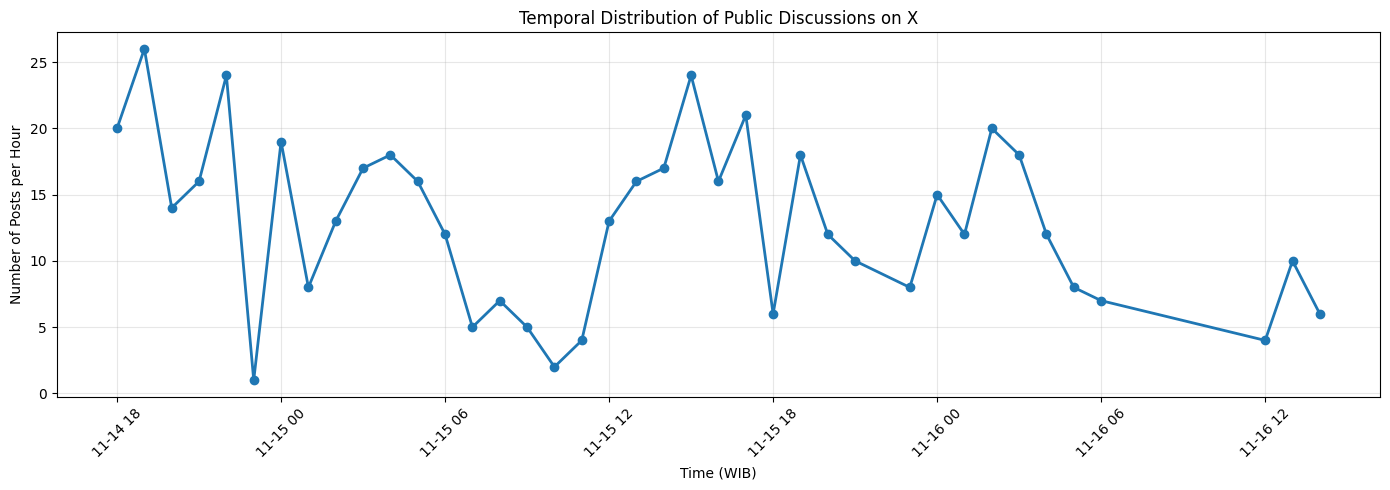

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    hourly_posts['hour'],
    hourly_posts['post_count'],
    marker='o',
    linewidth=2
)

plt.title('Temporal Distribution of Public Discussions on X')
plt.xlabel('Time (WIB)')
plt.ylabel('Number of Posts per Hour')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
peak_df = temporal_df[
    (temporal_df['created_at'] >= '2026-11-14 19:00:00+07:00') &
    (temporal_df['created_at'] < '2026-11-14 20:00:00+07:00')
].copy()

print("Total unggahan:", len(peak_df))
print("Jumlah akun unik:", peak_df['user_id_str'].nunique())

print("\nAkun paling aktif:")
display(
    peak_df.groupby('username')
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print("\nDaftar unggahan:")
display(
    peak_df[['created_at', 'username', 'full_text']]
    .sort_values('created_at')
)

Total unggahan: 26
Jumlah akun unik: 25

Akun paling aktif:


,0
username,
Iove_deepseek,2
DedynurPalakka,1
HanaGata1495,1
Heytherehojo,1
MuhamadLut8589,1
PapaSinamb94529,1
RienJinato,1
TeddGus,1
_Sadewa__,1



Daftar unggahan:


,created_at,username,full_text
479,2026-11-14 19:01:56+07:00,red_bean69,Gw gak dukung gibran gimana gimana juga. Tp kl...
478,2026-11-14 19:08:22+07:00,membarcaid,@komisarisnetzen Tapi emang harusnya goals nya...
477,2026-11-14 19:09:23+07:00,suka_matcha23,Gibran sudah mundur loh masih diserang. Serang...
476,2026-11-14 19:11:14+07:00,tandaglobalnews,Peluang Gibran maju pada Pilpres 2029 disebut ...
475,2026-11-14 19:11:15+07:00,anseriousdept,NAJIS TAI gak peduli old gibran kek new gibran...
474,2026-11-14 19:12:31+07:00,ibn_sjamsu,"Masalahnya, apakah Prabowo jantan untuk mundur..."
473,2026-11-14 19:16:28+07:00,Heytherehojo,Licik bgt main mundur sebelum dipecat. Enak bg...
472,2026-11-14 19:16:35+07:00,TeddGus,"Gibran mundur, Teddy Gusnaidi Puji Puan &amp; ..."
471,2026-11-14 19:24:00+07:00,Iove_deepseek,Teruslah bikin hate post tentang gibran nyatan...
470,2026-11-14 19:27:19+07:00,Iove_deepseek,Kasian bgt @rumichichichi teruslah hate speech...


In [ ]:
print("Kolom peak_df:")
print(peak_df.columns.tolist())

print("\nKolom sentiment_df:")
print(sentiment_df.columns.tolist())

Kolom peak_df:
['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username', 'normalisasi', 'original_text', 'coord_text', 'hour']

Kolom sentiment_df:
['created_at', 'full_text', 'cleaning', 'case_folding', 'normalisasi', 'tokenize', 'stopword removal', 'stemming_data', 'sent_label', 'sent_score']


In [ ]:
sentiment_df = pd.read_excel('hasillabeling_miniproject.xlsx')

print("Kolom sentiment dataset:")
print(sentiment_df.columns.tolist())

display(sentiment_df.head())

Kolom sentiment dataset:
['created_at', 'full_text', 'cleaning', 'case_folding', 'normalisasi', 'tokenize', 'stopword removal', 'stemming_data', 'sent_label', 'sent_score']


,created_at,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,stemming_data,sent_label,sent_score
0,2026-11-16 07:30:34,@BebySoSweet Saya selalu bilang di medsos klo ...,Saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos klo mrk berdua i...,saya selalu bilang di medsos kalau mereka berd...,"['saya', 'selalu', 'bilang', 'di', 'medsos', '...","['bilang', 'medsos', 'berdua', 'deal', 'khusus...",bilang medsos dua deal khusus dukung jokowi pr...,NEGATIVE,0.999944
1,2026-11-16 07:30:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",Dari Anies hingga Mahfud MD Intip Tokoh Masuk...,dari anies hingga mahfud md intip tokoh masuk...,dari anies hingga mahfud md intip tokoh masuk ...,"['dari', 'anies', 'hingga', 'mahfud', 'md', 'i...","['anies', 'mahfud', 'md', 'intip', 'tokoh', 'm...",anies mahfud md intip tokoh masuk bursa ganti ...,NEUTRAL,0.999917
2,2026-11-16 07:30:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,FAIZ Adalah Hero baru\n\nWartawan Gibran mundu...,faiz adalah hero baru\n\nwartawan gibran mundu...,faiz adalah hero baru wartawan gibran mundur m...,"['faiz', 'adalah', 'hero', 'baru', 'wartawan',...","['faiz', 'hero', 'wartawan', 'gibran', 'mundur...",faiz hero wartawan gibran mundur turut ganti f...,NEGATIVE,0.999842
3,2026-11-16 07:30:00,BACOT SELVIE‼️\n\nSUAMI LU PAS MAU MUNDUR AJA ...,BACOT SELVIE\n\nSUAMI LU PAS MAU MUNDUR AJA SO...,bacot selvie\n\nsuami lu pas mau mundur aja so...,bacot selvie suami kamu pas mau mundur saja so...,"['bacot', 'selvie', 'suami', 'kamu', 'pas', 'm...","['bacot', 'selvie', 'suami', 'pas', 'mundur', ...",bacot selvie suami pas mundur sok posting giat...,NEGATIVE,0.999954
4,2026-11-16 07:21:55,@hariyangkut Belajar lg utk menganalisa situas...,Belajar lg utk menganalisa situasi perpolitik...,belajar lg utk menganalisa situasi perpolitik...,belajar lagi untuk menganalisa situasi perpoli...,"['belajar', 'lagi', 'untuk', 'menganalisa', 's...","['belajar', 'menganalisa', 'situasi', 'perpoli...",ajar menganalisa situasi politik bro bukan ban...,NEGATIVE,0.999933


In [ ]:
# Samakan format timestamp
coord_df['created_at'] = pd.to_datetime(
    coord_df['created_at'], utc=True
)

sentiment_df['created_at'] = pd.to_datetime(
    sentiment_df['created_at'], utc=True
)

# Periksa jumlah data
print("Data crawling:", len(coord_df))
print("Data labeling:", len(sentiment_df))

# Periksa apakah timestamp dan teks cocok
print(
    "Timestamp sama:",
    coord_df['created_at'].isin(sentiment_df['created_at']).sum()
)

print(
    "Teks sama:",
    coord_df['full_text'].isin(sentiment_df['full_text']).sum()
)

Data crawling: 500
Data labeling: 496
Timestamp sama: 496
Teks sama: 497


In [ ]:
print(
    "Timestamp duplikat di crawling:",
    coord_df['created_at'].duplicated().sum()
)

print(
    "Timestamp duplikat di labeling:",
    sentiment_df['created_at'].duplicated().sum()
)

Timestamp duplikat di crawling: 7
Timestamp duplikat di labeling: 7


In [ ]:
# gabungan timestamp dan teks
coord_df['match_key'] = (
    coord_df['created_at'].astype(str) + '|' +
    coord_df['full_text'].fillna('').astype(str)
)

sentiment_df['match_key'] = (
    sentiment_df['created_at'].astype(str) + '|' +
    sentiment_df['full_text'].fillna('').astype(str)
)

print(
    "Jumlah pasangan unik crawling:",
    coord_df['match_key'].nunique()
)

print(
    "Jumlah pasangan unik labeling:",
    sentiment_df['match_key'].nunique()
)

print(
    "Pasangan yang cocok:",
    coord_df['match_key'].isin(sentiment_df['match_key']).sum()
)

Jumlah pasangan unik crawling: 500
Jumlah pasangan unik labeling: 496
Pasangan yang cocok: 496


In [ ]:
# tidak ada kunci duplikat
print("Duplikat kunci crawling:", coord_df['match_key'].duplicated().sum())
print("Duplikat kunci labeling:", sentiment_df['match_key'].duplicated().sum())

Duplikat kunci crawling: 0
Duplikat kunci labeling: 0


In [ ]:
peak_sentiment = peak_df.copy()

peak_sentiment['match_key'] = (
    peak_sentiment['created_at'].astype(str) + '|' +
    peak_sentiment['full_text'].fillna('').astype(str)
)

peak_sentiment = peak_sentiment.merge(
    sentiment_df[['match_key', 'sent_label']],
    on='match_key',
    how='left',
    validate='one_to_one'
)

print("Total unggahan:", len(peak_sentiment))
print("Label ditemukan:", peak_sentiment['sent_label'].notna().sum())
print("Label tidak ditemukan:", peak_sentiment['sent_label'].isna().sum())

Total unggahan: 26
Label ditemukan: 0
Label tidak ditemukan: 26


In [ ]:
print("=== DATA CRAWLING ===")
print(repr(coord_df['created_at'].iloc[0]))
print(repr(coord_df['full_text'].iloc[0]))

print("\n=== DATA LABELING ===")
print(repr(sentiment_df['created_at'].iloc[0]))
print(repr(sentiment_df['full_text'].iloc[0]))

=== DATA CRAWLING ===
Timestamp('2026-11-16 07:30:34+0000', tz='UTC')
'@BebySoSweet Saya selalu bilang di medsos klo mrk berdua itu ada deal2 khusus di balik dukungan Jokowi ke Prabowo jadi presiden. Skrg Gibran dituntut mundur sm rakyat, pasti ada lagi deal2 antara mrk berdua itu saling menutupi &amp; membela DOSA masing2. Loe berani ke gw, gw BONGKAR. Gitu kira2.'

=== DATA LABELING ===
Timestamp('2026-11-16 07:30:34+0000', tz='UTC')
'@BebySoSweet Saya selalu bilang di medsos klo mrk berdua itu ada deal2 khusus di balik dukungan Jokowi ke Prabowo jadi presiden. Skrg Gibran dituntut mundur sm rakyat, pasti ada lagi deal2 antara mrk berdua itu saling menutupi &amp; membela DOSA masing2. Loe berani ke gw, gw BONGKAR. Gitu kira2.'


In [ ]:
print(
    "Contoh teks crawling:",
    coord_df['full_text'].iloc[0][:200]
)

print(
    "\nContoh teks labeling:",
    sentiment_df['full_text'].iloc[0][:200]
)

Contoh teks crawling: @BebySoSweet Saya selalu bilang di medsos klo mrk berdua itu ada deal2 khusus di balik dukungan Jokowi ke Prabowo jadi presiden. Skrg Gibran dituntut mundur sm rakyat, pasti ada lagi deal2 antara mrk 

Contoh teks labeling: @BebySoSweet Saya selalu bilang di medsos klo mrk berdua itu ada deal2 khusus di balik dukungan Jokowi ke Prabowo jadi presiden. Skrg Gibran dituntut mundur sm rakyat, pasti ada lagi deal2 antara mrk 


In [ ]:
print("Timestamp peak_df:")
display(peak_df[['created_at', 'full_text']].head(3))

print("\nTimestamp sentiment_df:")
display(sentiment_df[['created_at', 'full_text', 'sent_label']].head(3))

Timestamp peak_df:


,created_at,full_text
454,2026-11-14 19:53:06+07:00,gibran mundur jadi wapres juga gara2 fans ling...
455,2026-11-14 19:50:35+07:00,@Dahnilanzar @gibran_tweet Pesan Gibran ke Rel...
456,2026-11-14 19:50:18+07:00,Kegilaan Termul.☠️\n\nGibran yg ajukan suket.\...



Timestamp sentiment_df:


,created_at,full_text,sent_label
0,2026-11-16 07:30:34+00:00,@BebySoSweet Saya selalu bilang di medsos klo ...,NEGATIVE
1,2026-11-16 07:30:00+00:00,"Dari Anies hingga Mahfud MD, Intip 8 Tokoh Mas...",NEUTRAL
2,2026-11-16 07:30:00+00:00,FAIZ Adalah Hero baru\n\nWartawan: Gibran mund...,NEGATIVE


In [ ]:
coord_df['created_at'] = pd.to_datetime(
    coord_df['created_at'],
    utc=True
).dt.tz_convert('Asia/Jakarta')

sentiment_df['created_at'] = pd.to_datetime(
    sentiment_df['created_at'],
    utc=True
).dt.tz_convert('Asia/Jakarta')

In [ ]:
peak_df = coord_df[
    (coord_df['created_at'] >= pd.Timestamp('2026-11-14 19:00:00', tz='Asia/Jakarta')) &
    (coord_df['created_at'] < pd.Timestamp('2026-11-14 20:00:00', tz='Asia/Jakarta'))
].copy()

print("Jumlah unggahan:", len(peak_df))

display(peak_df[['created_at', 'username', 'full_text']])

Jumlah unggahan: 26


,created_at,username,full_text
454,2026-11-14 19:53:06+07:00,ormsdimple27,gibran mundur jadi wapres juga gara2 fans ling...
455,2026-11-14 19:50:35+07:00,kasmatinzaghi,@Dahnilanzar @gibran_tweet Pesan Gibran ke Rel...
456,2026-11-14 19:50:18+07:00,_Sadewa__,Kegilaan Termul.☠️\n\nGibran yg ajukan suket.\...
457,2026-11-14 19:46:03+07:00,alexanderdrspan,@ardi_tama1 Sebenarnya Prabowo tidak ingin jug...
458,2026-11-14 19:45:50+07:00,elfianMAN,"@Franken_blues Udeh deal sama Jokowi, Gibran b..."
459,2026-11-14 19:45:47+07:00,PapaSinamb94529,@ade206 Saya sampai 5 x nonton gibran nyatakan...
460,2026-11-14 19:44:03+07:00,indragunartono,Lebih ke sebenernya skrg ini Gibran masih wapr...
461,2026-11-14 19:41:42+07:00,shibaainou,"Buat yg belum tau, dia tetep dapet gaji 20jt p..."
462,2026-11-14 19:41:12+07:00,indespic,Gibran emang kompetensinya sebatas shitposting...
463,2026-11-14 19:40:33+07:00,RienJinato,"Sebelum Mundur, Gibran Ungkap Pesan Prabowo ke..."


In [ ]:
# kunci pencocokan
for df in [peak_df, sentiment_df]:
    df['match_key'] = (
        df['created_at'].astype(str).str.strip() + '|' +
        df['full_text'].fillna('').astype(str).str.strip()
    )

# cekjumlah kecocokan
print(
    "Jumlah pasangan cocok:",
    peak_df['match_key'].isin(sentiment_df['match_key']).sum()
)

Jumlah pasangan cocok: 26


In [ ]:
peak_sentiment = peak_df.merge(
    sentiment_df[['match_key', 'sent_label']],
    on='match_key',
    how='left',
    validate='one_to_one'
)

print("Total unggahan:", len(peak_sentiment))
print("Label ditemukan:", peak_sentiment['sent_label'].notna().sum())
print("Label tidak ditemukan:", peak_sentiment['sent_label'].isna().sum())

Total unggahan: 26
Label ditemukan: 26
Label tidak ditemukan: 0


In [ ]:
sentiment_counts = (
    peak_sentiment['sent_label']
    .value_counts()
    .reindex(['NEGATIVE', 'NEUTRAL', 'POSITIVE'], fill_value=0)
)

print(sentiment_counts)

sent_label
NEGATIVE    18
NEUTRAL      5
POSITIVE     3
Name: count, dtype: int64


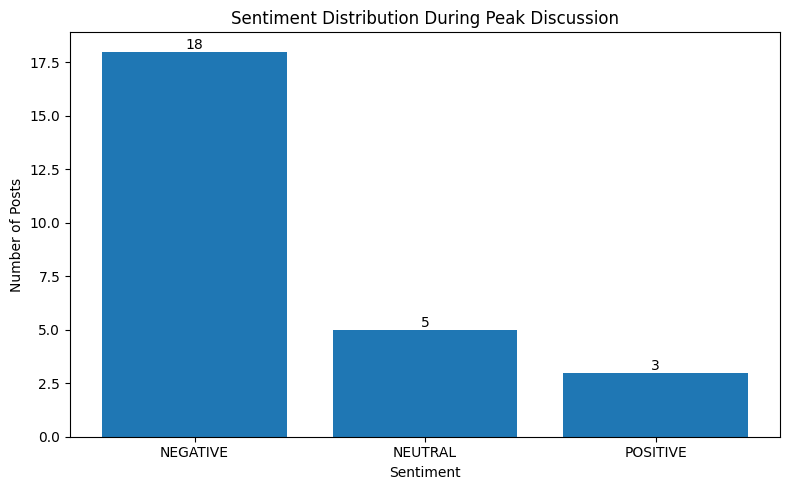

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)

plt.title('Sentiment Distribution During Peak Discussion')
plt.xlabel('Sentiment')
plt.ylabel('Number of Posts')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        int(bar.get_height()),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

In [ ]:
# kunci pencocokan di temporal_df
temporal_df['match_key'] = (
    temporal_df['created_at'].astype(str).str.strip() + '|' +
    temporal_df['full_text'].fillna('').astype(str).str.strip()
)

#match_key di sentiment_df tersedia
sentiment_df['match_key'] = (
    sentiment_df['created_at'].astype(str).str.strip() + '|' +
    sentiment_df['full_text'].fillna('').astype(str).str.strip()
)

In [ ]:
temporal_labeled = temporal_df.merge(
    sentiment_df[['match_key', 'sent_label']],
    on='match_key',
    how='inner'
)

print("Total data temporal:", len(temporal_df))
print("Total data berhasil dilabeli:", len(temporal_labeled))
print("Data tidak terpasangkan:", len(temporal_df) - len(temporal_labeled))

Total data temporal: 500
Total data berhasil dilabeli: 496
Data tidak terpasangkan: 4


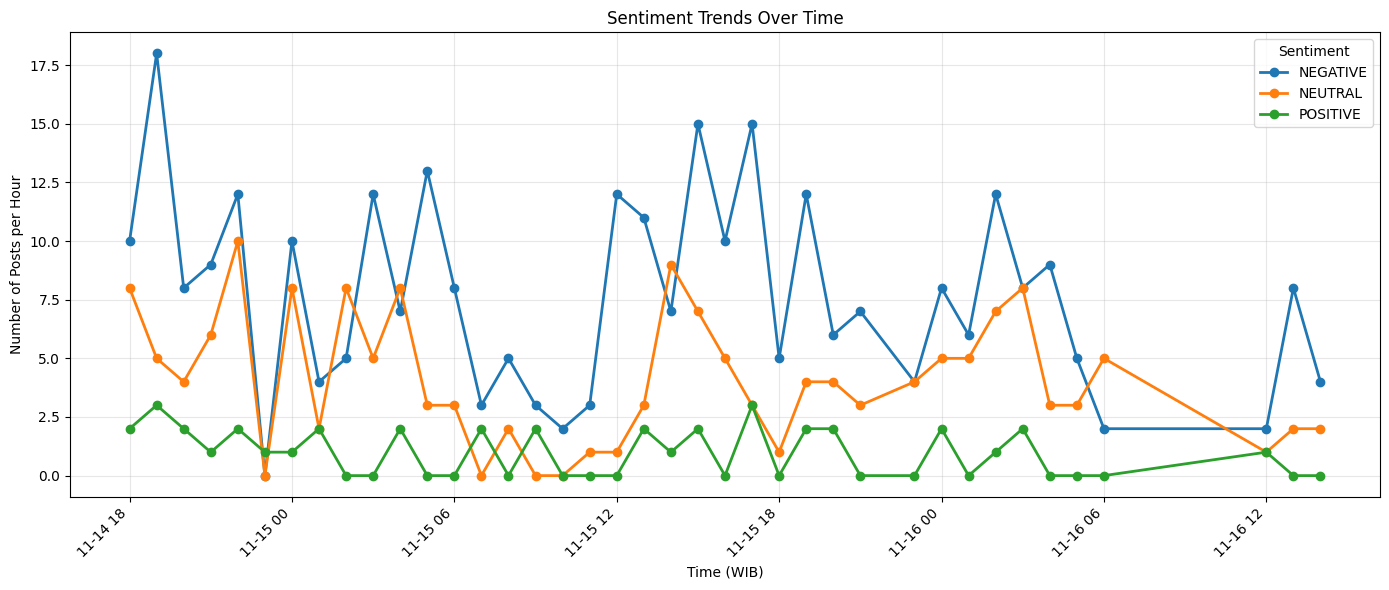

In [ ]:
temporal_labeled['hour'] = (
    temporal_labeled['created_at'].dt.floor('h')
)

sentiment_over_time = (
    temporal_labeled
    .groupby(['hour', 'sent_label'])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=['NEGATIVE', 'NEUTRAL', 'POSITIVE'],
        fill_value=0
    )
)

sentiment_over_time.plot(
    figsize=(14, 6),
    marker='o',
    linewidth=2
)

plt.title('Sentiment Trends Over Time')
plt.xlabel('Time (WIB)')
plt.ylabel('Number of Posts per Hour')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()